# EDA — данные новостной аналитики

Разбираем профили компаний, связи физлиц, платежи, банковские PDF и справочник Excel. Главные вопросы: что известно о компании, насколько надёжны связи между таблицами и что можно извлечь из документов.

Снимок анализа — **21.10.2026**. Расчёты локальные; исходные данные сохраняются без исправлений.

## Главное

- **85 525 строк профилей, 12 514 связей физлиц и 1 380 585 платёжных агрегатов.** Один ID соответствует 12 разным профилям; для объединения таблиц остаются 85 513 однозначных профилей.
- **601 значение выручки `1000` — техническая заглушка.** Сумма известных выручек выше 15 млрд у 341 группы; у 237 из них ни один участник отдельно не превышает порог. Это предварительный отбор: сумма не заменяет консолидированную выручку.
- **81,66% суммы платежей — самопереводы**, но это 13,29% операций и 1,99% строк. Профили обеих сторон известны примерно для 28,2% строк.
- **114 553 платёжных узла без однозначного профиля.** В связях физлиц профиль юрлица находится только для 36,99% строк.
- **9 PDF, 64 страницы, все без текстового слоя.** Есть отчёт 2021 года, ошибки OCR и повторяющиеся служебные страницы.
- **33 элемента профиля, 9 ролей, 149 источников в Excel.** Это описание нужного контекста, а не заполненные данные клиентов.

## Как запустить

Открыть `eda/00_EDA.ipynb`, выбрать интерпретатор `.venv/bin/python` из корня проекта и выполнить все ячейки. Рабочая папка ноутбука — `eda/`, корень проекта в коде — `Path("..")`. Данные лежат в `data/clients/`, PDF — в `data/reports/`, готовый OCR — в `data/pdf_ocr.json`. Справочник `company_research.xlsx` остаётся в корне. Папка `data/` исключена из Git; на другой машине нужен тот же набор файлов.

Зависимости закреплены в `eda/requirements.txt`. После их обновления перезапустить ядро ноутбука. Установка и повторный запуск из корня проекта:

```bash
.venv/bin/python -m pip install -r eda/requirements.txt
.venv/bin/python -m nbconvert --to notebook --execute --inplace eda/00_EDA.ipynb
```

HTML рядом с ноутбуком содержит готовые результаты и открывается без Python. Повторно распознавать PDF для запуска не нужно.

## 1. Источники и единицы наблюдения

| Файл | Что означает строка |
|---|---|
| `df_Uid_data_hack.csv` | Профиль юрлица; ID требует проверки уникальности |
| `df_Fid_Uid_link_hack.csv` | Связь физлица и юрлица; должность человека не указана |
| `df_Uid_payment_hack.csv` | Направленный платёжный агрегат; число операций хранится в `PAY_CNT` |
| PDF | Документ и страница; страница не обязательно отдельная новость |
| Excel | Элемент профиля, роль или потенциальный источник |

Первичный аудит включает все строки (`*_raw`). В объединениях исключены 12 неоднозначных профилей и 153 связанные платёжные строки; влияние этого отбора показано отдельно.

Материалы задания: [CSV](https://drive.google.com/drive/folders/1Ep8wWoEHTg5Q8kwrLx2j_xFyxGUEVxFq), [аналитика банка](https://drive.google.com/drive/folders/15xZTLF1lZ65p6o5xpNA_fRbxjoV-UlG1).


In [1]:
from datetime import date
from pathlib import Path
from textwrap import fill
from urllib.parse import urlsplit
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

SEED = 143
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110, "font.family": "DejaVu Sans"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 100)

ROOT = Path("..")
DATA = ROOT / "data"
WORKBOOK = ROOT / "company_research.xlsx"

companies_raw = pd.read_csv(DATA / "clients/df_Uid_data_hack.csv", sep=";", dtype="string")
links_raw = pd.read_csv(DATA / "clients/df_Fid_Uid_link_hack.csv", sep=";", dtype="string")
payments_raw = pd.read_csv(DATA / "clients/df_Uid_payment_hack.csv", sep=";", dtype="string")


In [2]:
raw = {"companies": companies_raw, "person_links": links_raw, "payments": payments_raw}
inventory = pd.DataFrame(
    [
        {
            "table": name,
            "rows": len(df),
            "columns": df.shape[1],
            "memory_MB": df.memory_usage(deep=True).sum() / 1e6,
            "duplicate_rows": int(df.duplicated().sum()),
            "missing_cells": int(df.isna().sum().sum()),
        }
        for name, df in raw.items()
    ]
)
display(inventory.round(2))
for name, df in raw.items():
    print(name)
    display(df.head(3))
assert list(links_raw.columns) == ["SYNTHETIC_F", "CITY_NAME", "RC_NAME", "SYNTHETIC_U"]
assert set(payments_raw) == {"PAYER", "BENEFICIARY", "PAY_AMT", "PAY_CNT"}
assert len(companies_raw.columns) == 24

,table,rows,columns,memory_MB,duplicate_rows,missing_cells
0,companies,85525,24,142.18,0,166693
1,person_links,12514,4,3.53,0,28
2,payments,1380585,4,303.82,1,0


companies


,SYNTHETIC_U,ORG_TYPE,OKFS_NAME,COMPANY_AGE_YEARS_GRADATION,ECO_MARK_LABEL,MAINOKVED_CODE,MAINOKVED_NAME,NEGATIVEMARK,AMOUNT_WORKERS_FNS_GRADATION,AMOUNT_WORKERS_SPARK_GRADATION,CL_TYPE,CL_PRODUCT_RKO_MARK,CL_PRODUCT_GAR_MARK,CL_PRODUCT_LOA_MARK,CL_PRODUCT_LEA_MARK,CL_PRODUCT_DEP_MARK,CL_PRODUCT_ZPP_MARK,FTS_FLAG,FTS_COUNTRY_NAME,FACTORING_MARK,REVENUE_COMPANY,GROUP_ID,CITY,REGION
0,U_67,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,16-25,Рождение,46.51,"Торговля оптовая компьютерами, периферийными устройствами к компьютерам и программным обеспечением",0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,136493.0,group_134463_sb,г. Новосибирск,Новосибирская область
1,U_76,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,16-25,Оптимизация,52.29,"Деятельность вспомогательная прочая, связанная с перевозками",0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,890376546.0,group_90087_sb,г. Новосибирск,Новосибирская область
2,U_80,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,16-25,Оптимизация,25.61,Обработка металлов и нанесение покрытий на металлы,0.0,16-100,<NA>,CLOSE_CLIENT,0.0,0.0,0.0,1.0,0.0,0.0,0.0,<NA>,0.0,1423218135.0,group_104611_sb,г. Екатеринбург,Свердловская область


person_links


,SYNTHETIC_F,CITY_NAME,RC_NAME,SYNTHETIC_U
0,F_64255,"Мск ""Юг""",МОСКОВСКИЙ,U_146717
1,F_2064,Омск,СИБИРСКИЙ,U_40653
2,F_67674,Москва,МОСКОВСКИЙ,U_155903


payments


,BENEFICIARY,PAYER,PAY_AMT,PAY_CNT
0,U_25835,U_144100,16157000.0,981
1,U_161844,U_89759,2748000.0,4
2,U_9104,U_344945,26000.0,21


CSV используют разделитель `;`. При загрузке все поля сохраняются как строки; числовые признаки преобразуются отдельно с проверкой ошибок. Это сохраняет идентификаторы и исходное представление ОКВЭД: например, код `41.20` при чтении как float теряет завершающий ноль.

## 2. Схема, пропуски и технические значения

| Поля | Смысл и единицы |
|---|---|
| `SYNTHETIC_U`, `GROUP_ID` | Анонимный ID юрлица и предоставленная группа компаний |
| `ORG_TYPE`, `OKFS_NAME` | Организационный тип и форма собственности |
| `COMPANY_AGE_YEARS_GRADATION`, `ECO_MARK_LABEL` | Возрастная категория и стадия развития бизнеса |
| `MAINOKVED_CODE`, `MAINOKVED_NAME` | Основной ОКВЭД и его название |
| `NEGATIVEMARK` | Наличие достоверных сведений о ключевом собственнике по Q&A; не метка риска |
| `AMOUNT_WORKERS_FNS_GRADATION`, `AMOUNT_WORKERS_SPARK_GRADATION` | Категория численности по ФНС / СПАРК, не точное число работников |
| `CL_TYPE` | `CLIENT` — действующий, `PROSPECT` — потенциальный, `CLOSE_CLIENT` — бывший клиент |
| `CL_PRODUCT_*_MARK` | Флаги продуктов: RKO — РКО, GAR — гарантии, LOA — кредиты, LEA — лизинг, DEP — депозиты, ZPP — зарплатный проект |
| `FACTORING_MARK` | Флаг факторинга |
| `FTS_FLAG`, `FTS_COUNTRY_NAME` | Сведения ФТС и перечисленные страны; направление, доли и валюты не заданы |
| `REVENUE_COMPANY` | Выручка в рублях за предыдущий год по пояснению; отдельного года в CSV нет |
| `CITY`, `REGION` | География регистрации компании |

Названия и трактовки сверены с материалами кейса и Q&A; диапазоны и пропуски ниже рассчитаны по фактическим файлам.


,field,missing,missing_pct,unique,example
0,SYNTHETIC_U,0,0.00,85514,"U_67, U_76, U_80"
1,ORG_TYPE,0,0.00,1,КОММ_ОРГ
2,OKFS_NAME,0,0.00,12,"ЧАСТНАЯ СОБСТВЕННОСТЬ, ИНАЯ СМЕШАННАЯ РОССИЙСКАЯ СОБСТВЕННОСТЬ, СОВМЕСТНАЯ ЧАСТНАЯ И ИНОСТРАННАЯ..."
3,COMPANY_AGE_YEARS_GRADATION,0,0.00,4,"16-25, 8-15, 4-7"
4,ECO_MARK_LABEL,4157,4.86,4,"Рождение, Оптимизация, Бизнес в новой реальности"
5,MAINOKVED_CODE,0,0.00,546,"46.51, 52.29, 25.61"
6,MAINOKVED_NAME,0,0.00,536,"Торговля оптовая компьютерами, периферийными устройствами к компьютерам и программным обеспечени..."
7,NEGATIVEMARK,0,0.00,2,"0.0, 1.0"
8,AMOUNT_WORKERS_FNS_GRADATION,0,0.00,4,"Менее 15, 16-100, 101-250"
9,AMOUNT_WORKERS_SPARK_GRADATION,85357,99.80,4,"16-100, Менее 15, 101-250"


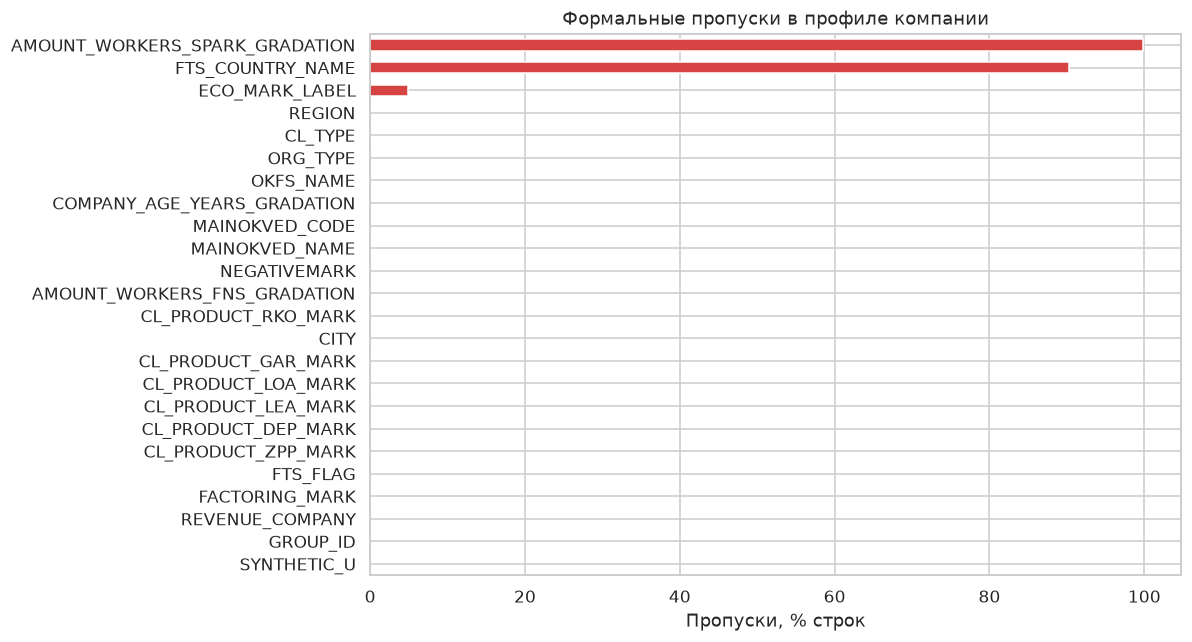

In [3]:
schema = pd.DataFrame(
    {
        "field": companies_raw.columns,
        "missing": companies_raw.isna().sum().values,
        "missing_pct": companies_raw.isna().mean().values * 100,
        "unique": companies_raw.nunique().values,
        "example": [", ".join(companies_raw[c].dropna().unique()[:3]) for c in companies_raw],
    }
)
display(schema.round(2))
fig, ax = plt.subplots(figsize=(11, 6))
schema.set_index("field").missing_pct.sort_values().plot.barh(ax=ax, color="#D54343")
ax.set(xlabel="Пропуски, % строк", ylabel="", title="Формальные пропуски в профиле компании")
plt.tight_layout()
plt.show()

,table,field,text_missing_tokens,surrounding_spaces
0,person_links,CITY_NAME,1,0
1,person_links,RC_NAME,8,0


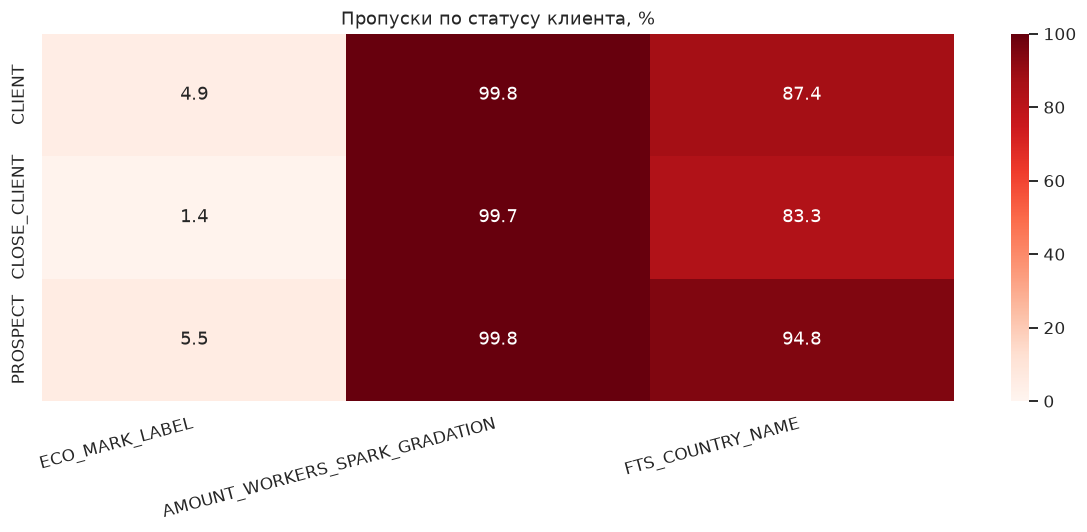

In [4]:
missing_tokens = {
    "",
    "null",
    "none",
    "nan",
    "n/a",
    "нет данных",
    "неизвестно",
    "не определено",
    "не определен",
    "не определён",
    "инн не определён",
    "-",
}
placeholder_audit = []
for table, df in raw.items():
    for col in df:
        stripped = df[col].str.strip()
        count = int(stripped.str.lower().isin(missing_tokens).sum())
        spaces = int((df[col].notna() & df[col].ne(stripped)).sum())
        if count or spaces:
            placeholder_audit.append([table, col, count, spaces])
display(
    pd.DataFrame(
        placeholder_audit, columns=["table", "field", "text_missing_tokens", "surrounding_spaces"]
    )
)
missing_by_client = companies_raw.groupby("CL_TYPE").apply(
    lambda g: g[["ECO_MARK_LABEL", "AMOUNT_WORKERS_SPARK_GRADATION", "FTS_COUNTRY_NAME"]]
    .isna()
    .mean()
    * 100,
    include_groups=False,
)
sns.heatmap(missing_by_client, annot=True, fmt=".1f", cmap="Reds", vmin=0, vmax=100)
plt.title("Пропуски по статусу клиента, %")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Пропуски SPARK остаются пропусками: отсутствие сведений о штате не означает нулевую численность. Заполненность стран рассматривается вместе с `FTS_FLAG`. Константный `ORG_TYPE` не различает компании в этом наборе.

## 3. Уникальность ключей и риск ошибочного join

In [5]:
duplicate_ids = companies_raw.loc[
    companies_raw.SYNTHETIC_U.duplicated(keep=False), "SYNTHETIC_U"
].unique()
ambiguous = set(duplicate_ids)
conflicts = companies_raw[companies_raw.SYNTHETIC_U.isin(ambiguous)]
display(conflicts)
display(conflicts.groupby("SYNTHETIC_U").nunique().T.rename(columns=lambda x: f"{x}: distinct"))
companies = companies_raw[~companies_raw.SYNTHETIC_U.isin(ambiguous)].copy()
assert companies.SYNTHETIC_U.is_unique
ids = set(companies.SYNTHETIC_U)
payment_ambiguous = payments_raw.PAYER.isin(ambiguous) | payments_raw.BENEFICIARY.isin(ambiguous)
link_ambiguous = links_raw.SYNTHETIC_U.isin(ambiguous)
display(
    pd.DataFrame(
        {
            "source": ["company rows", "payment rows", "person links"],
            "ambiguous_rows": [
                len(conflicts),
                int(payment_ambiguous.sum()),
                int(link_ambiguous.sum()),
            ],
        }
    )
)
print("Надёжно уникальных профилей:", len(companies))

,SYNTHETIC_U,ORG_TYPE,OKFS_NAME,COMPANY_AGE_YEARS_GRADATION,ECO_MARK_LABEL,MAINOKVED_CODE,MAINOKVED_NAME,NEGATIVEMARK,AMOUNT_WORKERS_FNS_GRADATION,AMOUNT_WORKERS_SPARK_GRADATION,CL_TYPE,CL_PRODUCT_RKO_MARK,CL_PRODUCT_GAR_MARK,CL_PRODUCT_LOA_MARK,CL_PRODUCT_LEA_MARK,CL_PRODUCT_DEP_MARK,CL_PRODUCT_ZPP_MARK,FTS_FLAG,FTS_COUNTRY_NAME,FACTORING_MARK,REVENUE_COMPANY,GROUP_ID,CITY,REGION
85513,U_428697,КОММ_ОРГ,СОБСТВЕННОСТЬ ИНОСТРАННЫХ ГРАЖДАН И ЛИЦ БЕЗ ГРАЖДАНСТВА,0-3,<NA>,46.90,Торговля оптовая неспециализированная,0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,23619981.0,group_91277_sb,г. Москва,Москва
85514,U_428697,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,8-15,Бизнес в новой реальности,41.20,Строительство жилых и нежилых зданий,0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,236263.0,group_7498_sb,г. Челябинск,Челябинская область
85515,U_428697,КОММ_ОРГ,СОБСТВЕННОСТЬ ИНОСТРАННЫХ ГРАЖДАН И ЛИЦ БЕЗ ГРАЖДАНСТВА,0-3,<NA>,46.45,Торговля оптовая парфюмерными и косметическими товарами,0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,57872.0,group_134696_sb,г. Москва,Москва
85516,U_428697,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,8-15,Оптимизация,41.2,Строительство жилых и нежилых зданий,1.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,79177.0,group_134833_sb,г. Казань,Республика Татарстан
85517,U_428697,КОММ_ОРГ,СОБСТВЕННОСТЬ ИНОСТРАННЫХ ГРАЖДАН И ЛИЦ БЕЗ ГРАЖДАНСТВА,0-3,<NA>,47.91,Торговля розничная по почте или по информационно-коммуникационной сети Интернет,0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,46320658.0,group_92057_sb,г. Москва,Москва
85518,U_428697,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,4-7,Бизнес в новой реальности,93.19,Деятельность в области спорта прочая,0.0,Менее 15,Менее 15,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,227010.0,group_9171_sb,г. Санкт-Петербург,Санкт-Петербург
85519,U_428697,КОММ_ОРГ,СОБСТВЕННОСТЬ ИНОСТРАННЫХ ГРАЖДАН И ЛИЦ БЕЗ ГРАЖДАНСТВА,0-3,<NA>,46.73,"Торговля оптовая лесоматериалами, строительными материалами и санитарно-техническим оборудованием",0.0,16-100,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,12881354.0,group_29468_sb,г. Москва,Москва
85520,U_428697,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,8-15,Бизнес в новой реальности,52.29,"Деятельность вспомогательная прочая, связанная с перевозками",0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,51427.0,group_90099_sb,г. Самара,Самарская область
85521,U_428697,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,0-3,<NA>,46.73,"Торговля оптовая лесоматериалами, строительными материалами и санитарно-техническим оборудованием",0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,739757751.0,group_90293_sb,г. Москва,Москва
85522,U_428697,КОММ_ОРГ,ЧАСТНАЯ СОБСТВЕННОСТЬ,16-25,Бизнес в новой реальности,68.32.1,Управление эксплуатацией жилого фонда за вознаграждение или на договорной основе,0.0,Менее 15,<NA>,PROSPECT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,<NA>,0.0,44290.0,group_86361_sb,г. Тольятти,Самарская область


SYNTHETIC_U,U_428697: distinct
ORG_TYPE,1
OKFS_NAME,2
COMPANY_AGE_YEARS_GRADATION,4
ECO_MARK_LABEL,2
MAINOKVED_CODE,10
MAINOKVED_NAME,9
NEGATIVEMARK,2
AMOUNT_WORKERS_FNS_GRADATION,2
AMOUNT_WORKERS_SPARK_GRADATION,1
CL_TYPE,1


,source,ambiguous_rows
0,company rows,12
1,payment rows,153
2,person links,0


Надёжно уникальных профилей: 85513


Один ID встречается в 12 профилях с разными регионами, группами, отраслями и выручкой. `drop_duplicates("SYNTHETIC_U")` оставил бы произвольную запись. Поэтому все 12 строк исключены из объединений, но сохранены в исходной таблице.

В Q&A этот случай объяснён обезличиванием пустых записей. В текущем файле выбрать правильный профиль невозможно.

## 4. Статусы клиентов и продуктовые признаки


,rows,share_pct
CL_TYPE,,
CLIENT,41968,49.07
PROSPECT,36699,42.91
CLOSE_CLIENT,6858,8.02


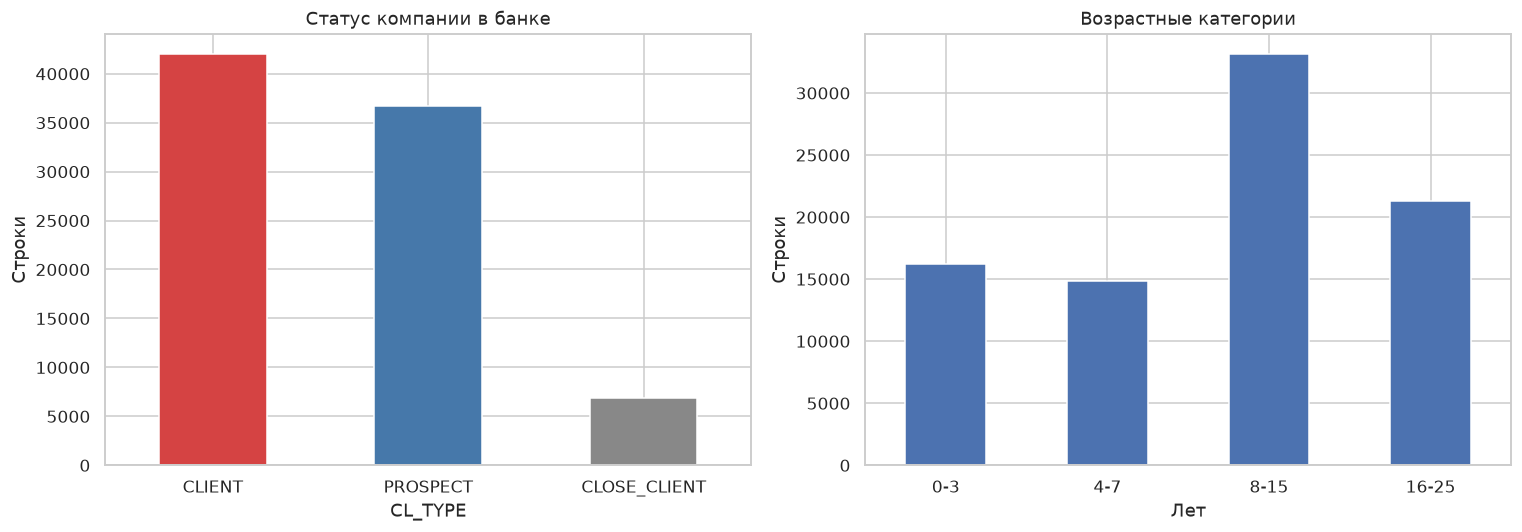

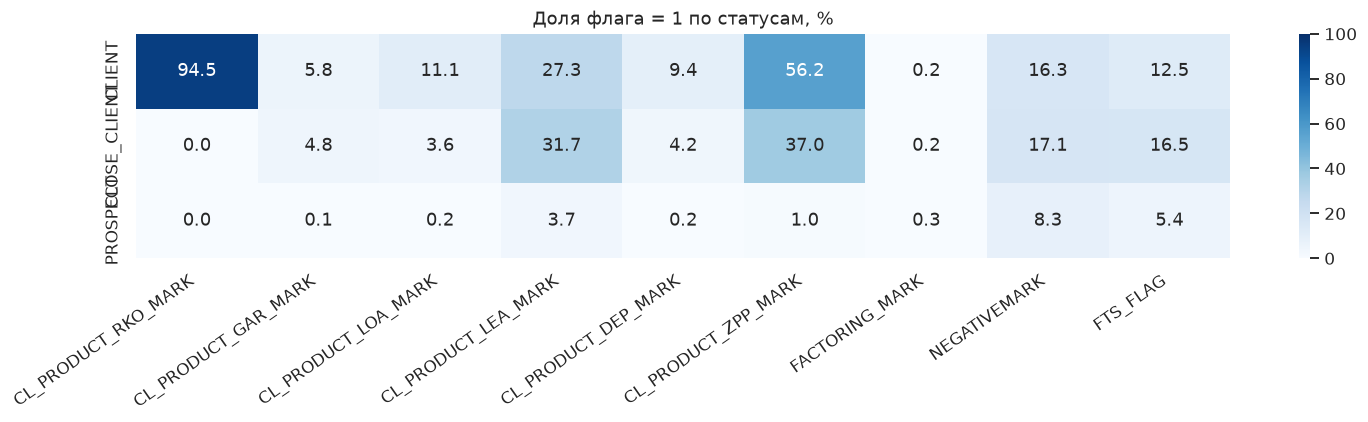

,share
FACTORING_MARK,0.002491
CL_PRODUCT_GAR_MARK,0.032603
CL_PRODUCT_DEP_MARK,0.050086
CL_PRODUCT_LOA_MARK,0.057827
FTS_FLAG,0.09781
NEGATIVEMARK,0.129512
CL_PRODUCT_LEA_MARK,0.175541
CL_PRODUCT_ZPP_MARK,0.309707
CL_PRODUCT_RKO_MARK,0.463824


,profiles,share_pct
OKFS_NAME,,
ЧАСТНАЯ СОБСТВЕННОСТЬ,82275,96.21
СОВМЕСТНАЯ ЧАСТНАЯ И ИНОСТРАННАЯ СОБСТВЕННОСТЬ,1130,1.32
СОБСТВЕННОСТЬ ИНОСТРАННЫХ ГРАЖДАН И ЛИЦ БЕЗ ГРАЖДАНСТВА,851,1.0
СОБСТВЕННОСТЬ ИНОСТРАННЫХ ЮРИДИЧЕСКИХ ЛИЦ,728,0.85
ФЕДЕРАЛЬНАЯ СОБСТВЕННОСТЬ,167,0.2
ИНАЯ СМЕШАННАЯ РОССИЙСКАЯ СОБСТВЕННОСТЬ,94,0.11
СМЕШАННАЯ РОССИЙСКАЯ СОБСТВЕННОСТЬ С ДОЛЕЙ ФЕДЕРАЛЬНОЙ СОБСТВЕННОСТИ,85,0.1
СМЕШАННАЯ РОССИЙСКАЯ СОБСТВЕННОСТЬ С ДОЛЕЙ СОБСТВЕННОСТИ СУБЪЕКТОВ РОССИЙСКОЙ ФЕДЕРАЦИИ,65,0.08
СОБСТВЕННОСТЬ СУБЪЕКТОВ РОССИЙСКОЙ ФЕДЕРАЦИИ,52,0.06


,profiles,share_pct
ECO_MARK_LABEL,,
Оптимизация,51156,59.82
Бизнес в новой реальности,25274,29.56
Нет данных,4151,4.85
Рождение,3372,3.94
Стремительный рост,1560,1.82


In [6]:
status = companies_raw.CL_TYPE.value_counts().rename_axis("CL_TYPE").to_frame("rows")
status["share_pct"] = status.rows / len(companies_raw) * 100
display(status.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
status.rows.plot.bar(ax=axes[0], rot=0, color=["#D54343", "#4678AA", "#888888"])
axes[0].set(title="Статус компании в банке", ylabel="Строки")
companies_raw.COMPANY_AGE_YEARS_GRADATION.value_counts().reindex(
    ["0-3", "4-7", "8-15", "16-25"]
).plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Возрастные категории", xlabel="Лет", ylabel="Строки")
plt.tight_layout()
plt.show()
flags = [c for c in companies if c.endswith("_MARK")] + ["NEGATIVEMARK", "FTS_FLAG"]
for col in flags:
    assert set(companies[col].dropna()) <= {"0.0", "1.0"}, col
    companies[col] = pd.to_numeric(companies[col]).astype("Int8")
flag_rates = companies.groupby("CL_TYPE")[flags].mean() * 100
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(flag_rates.astype(float), annot=True, fmt=".1f", cmap="Blues", ax=ax, vmin=0, vmax=100)
ax.set(title="Доля флага = 1 по статусам, %", xlabel="", ylabel="")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
display(companies[flags].mean().sort_values().rename("share").to_frame())
for field in ["OKFS_NAME", "ECO_MARK_LABEL"]:
    counts = companies[field].fillna("Нет данных").value_counts().rename("profiles").to_frame()
    counts["share_pct"] = counts.profiles / len(companies) * 100
    display(counts.round(2))

Для сценария интернет-банка отдельно смотрим `CLIENT`; остальные статусы нужны для сравнения и анализа связей. По Q&A, `NEGATIVEMARK=1` означает **наличие достоверных сведений о ключевом собственнике**. Название поля сбивает с толку: это не метка риска.

## 5. Выручка: заглушки, хвосты и масштаб бизнеса


,rows
parse_error,0
nonfinite,0
negative,0
zero,0
placeholder_1000,601
positive_below_1000,0


,revenue_raw,revenue_valid
count,85513.0,84912.0
mean,379762550.84,382450471.18
std,1425343849.92,1430019854.46
min,1000.0,1001.0
1%,1172.12,4275.99
25%,885263.0,1060295.0
50%,33605933.0,34612402.5
75%,240169243.0,243919819.5
90%,910168195.8,918793897.3
95%,1665911675.4,1674632792.0


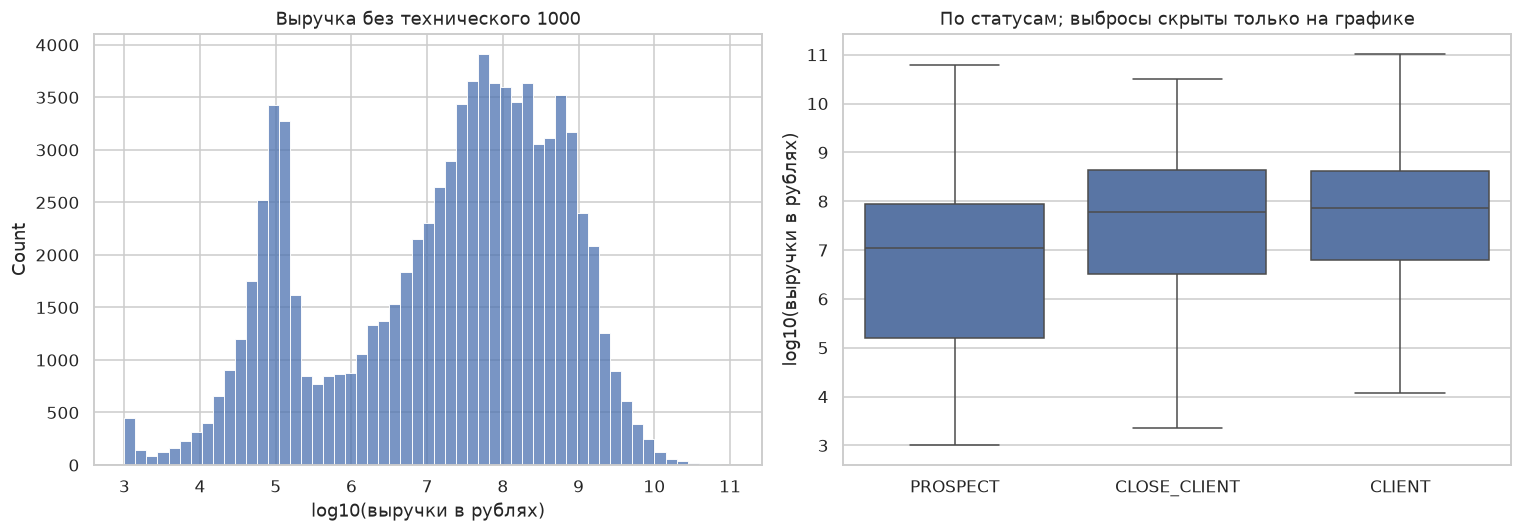

,count,median,mean,max
CL_TYPE,,,,
CLIENT,41748,73930951.0,527800252.73,105596467908.0
CLOSE_CLIENT,6812,58939553.5,437951813.21,31046755094.0
PROSPECT,36352,10945025.5,205124936.91,62005544532.0


In [7]:
revenue_raw = pd.to_numeric(companies_raw.REVENUE_COMPANY, errors="coerce")
companies["revenue_raw"] = pd.to_numeric(companies.REVENUE_COMPANY, errors="coerce")
companies["revenue_valid"] = companies.revenue_raw.where(
    companies.revenue_raw.gt(0)
    & companies.revenue_raw.ne(1000)
    & np.isfinite(companies.revenue_raw)
)
revenue_audit = pd.Series(
    {
        "parse_error": int(revenue_raw.isna().sum()),
        "nonfinite": int((~np.isfinite(revenue_raw)).sum()),
        "negative": int(revenue_raw.lt(0).sum()),
        "zero": int(revenue_raw.eq(0).sum()),
        "placeholder_1000": int(revenue_raw.eq(1000).sum()),
        "positive_below_1000": int(revenue_raw.between(0, 1000, inclusive="neither").sum()),
    }
)
display(revenue_audit.to_frame("rows"))
display(
    companies[["revenue_raw", "revenue_valid"]]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
    .round(2)
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(np.log10(companies.revenue_valid.dropna()), bins=55, ax=axes[0])
axes[0].set(xlabel="log10(выручки в рублях)", title="Выручка без технического 1000")
sns.boxplot(
    data=companies.assign(log_revenue=np.log10(companies.revenue_valid)),
    x="CL_TYPE",
    y="log_revenue",
    ax=axes[1],
    showfliers=False,
)
axes[1].set(
    ylabel="log10(выручки в рублях)",
    xlabel="",
    title="По статусам; выбросы скрыты только на графике",
)
plt.tight_layout()
plt.show()
display(companies.groupby("CL_TYPE").revenue_valid.agg(["count", "median", "mean", "max"]).round(2))

In [8]:
valid_revenue = companies.revenue_valid.dropna().sort_values(ascending=False)
concentration = pd.DataFrame(
    [
        {
            "top_pct": pct,
            "companies": max(1, int(np.ceil(len(valid_revenue) * pct / 100))),
            "revenue_share_pct": valid_revenue.iloc[
                : max(1, int(np.ceil(len(valid_revenue) * pct / 100)))
            ].sum()
            / valid_revenue.sum()
            * 100,
        }
        for pct in [0.1, 1, 5, 10]
    ]
)
display(concentration.round(2))
display(
    companies.nlargest(10, "revenue_valid")[
        ["SYNTHETIC_U", "CL_TYPE", "GROUP_ID", "MAINOKVED_CODE", "REGION", "revenue_valid"]
    ]
)
q1, q3 = valid_revenue.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("Выше обычной IQR-границы:", int(valid_revenue.gt(upper).sum()), "из", len(valid_revenue))

,top_pct,companies,revenue_share_pct
0,0.1,85,7.59
1,1.0,850,27.02
2,5.0,4246,55.93
3,10.0,8492,72.16


,SYNTHETIC_U,CL_TYPE,GROUP_ID,MAINOKVED_CODE,REGION,revenue_valid
14221,U_57706,CLIENT,group_134402_sb,46.71,Москва,105596467908.0
2405,U_9250,CLIENT,group_133188_sb,42.99,Иркутская область,62340483339.0
78250,U_408263,PROSPECT,group_134761_sb,46.90,Москва,62005544532.0
6507,U_26030,CLIENT,group_133767_sb,46.71.2,Башкортостан (Республика),60403064363.0
44400,U_200890,CLIENT,group_134320_sb,46.72,Челябинская область,59603929469.0
50202,U_234228,CLIENT,group_134238_sb,46.90,Москва,56550494048.0
24698,U_102920,CLIENT,group_133117_sb,46.38,Санкт-Петербург,54767618087.0
9424,U_34911,CLIENT,group_133081_sb,46.21,Ростовская область,53868155228.0
11186,U_45612,CLIENT,group_133355_sb,46.71.2,Москва,47466583782.0
77388,U_408046,PROSPECT,group_134545_sb,41.20,Москва,45982978116.0


Выше обычной IQR-границы: 12480 из 84912


По пояснению организаторов, выручка `1000` — техническая заглушка; в расчётах она заменена пропуском. Крупные значения оставлены: длинный правый хвост ожидаем для бизнеса разного масштаба. Граница IQR здесь только описывает распределение.

Выручка задана в рублях за предыдущий отчётный год, но отдельного года в CSV нет. Сравнивать её с суммой платежей как финансовый коэффициент нельзя без периода платежной выгрузки.

## 6. Группы компаний и порог 15 млрд рублей


,members,known_revenue,revenue_sum,largest_member,clients,regions,industries
count,18091.00,18091.0,18071.0,18071.0,18091.00,18091.00,18091.00
mean,4.73,4.69,1797057960.77,1204060406.05,2.32,1.37,2.60
std,21.47,21.28,5954781739.79,2702798969.33,8.91,1.68,7.47
min,1.00,0.0,1002.0,1002.0,0.00,1.00,1.00
50%,1.00,1.0,609641954.0,557850326.0,1.00,1.00,1.00
90%,4.00,4.0,3344523658.0,2646883495.0,3.00,2.00,3.00
95%,10.00,10.0,6472762309.5,4484731198.0,6.00,3.00,6.00
99%,103.00,101.1,24268304461.299999,11131990392.6,42.00,10.00,45.00
max,624.00,621.0,302726046209.0,105596467908.0,272.00,35.00,136.00


,value
groups,18091
single_member_groups,12863
groups_sum_above_15bn,341
groups_with_member_above_15bn,104
sum_only_candidates,237
clients_in_candidate_groups,13601
candidate_groups_incomplete_revenue,152


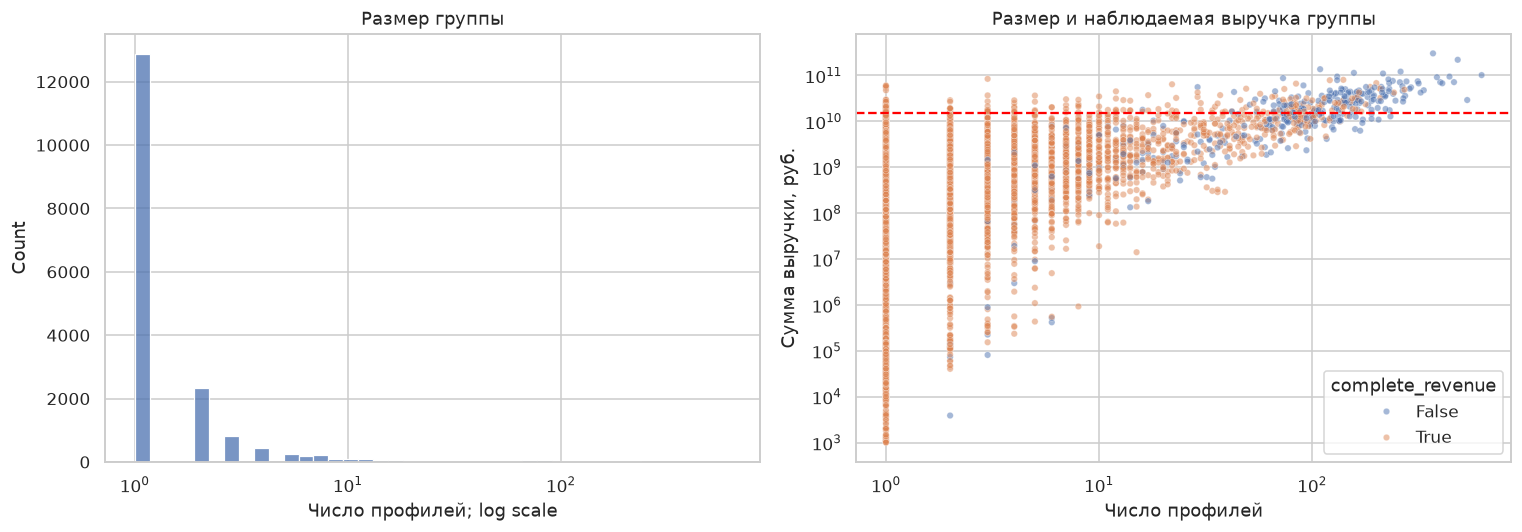

,members,known_revenue,revenue_sum,largest_member,clients,regions,industries,complete_revenue,sum_above_15bn,member_above_15bn
GROUP_ID,,,,,,,,,,
group_134402_sb,369,366,302726046209.0,105596467908.0,115,31,114,False,True,True
group_134409_sb,482,478,219465842665.0,42729015917.0,126,12,109,False,True,True
group_134761_sb,109,105,136876948851.0,62005544532.0,5,6,27,False,True,True
group_134457_sb,260,258,121097512099.0,22437829901.0,114,15,87,False,True,True
group_134498_sb,157,156,113782288326.0,16556035018.0,33,16,72,False,True,True
group_134460_sb,215,213,110258911595.0,44401187115.0,116,17,78,False,True,True
group_134404_sb,624,621,101739155593.0,8566755000.0,272,29,135,False,True,False
group_134545_sb,131,130,94650842406.0,45982978116.0,60,7,58,False,True,True
group_134407_sb,441,439,94480358557.0,9673602491.0,169,16,121,False,True,False


In [9]:
groups = companies.groupby("GROUP_ID").agg(
    members=("SYNTHETIC_U", "size"),
    known_revenue=("revenue_valid", "count"),
    revenue_sum=("revenue_valid", lambda s: s.sum(min_count=1)),
    largest_member=("revenue_valid", "max"),
    clients=("CL_TYPE", lambda s: s.eq("CLIENT").sum()),
    regions=("REGION", "nunique"),
    industries=("MAINOKVED_CODE", "nunique"),
)
groups["complete_revenue"] = groups.known_revenue.eq(groups.members)
groups["sum_above_15bn"] = groups.revenue_sum.gt(15e9)
groups["member_above_15bn"] = groups.largest_member.gt(15e9)
display(groups.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))
display(
    pd.Series(
        {
            "groups": len(groups),
            "single_member_groups": int(groups.members.eq(1).sum()),
            "groups_sum_above_15bn": int(groups.sum_above_15bn.sum()),
            "groups_with_member_above_15bn": int(groups.member_above_15bn.sum()),
            "sum_only_candidates": int((groups.sum_above_15bn & ~groups.member_above_15bn).sum()),
            "clients_in_candidate_groups": int(groups.loc[groups.sum_above_15bn, "clients"].sum()),
            "candidate_groups_incomplete_revenue": int(
                (groups.sum_above_15bn & ~groups.complete_revenue).sum()
            ),
        }
    ).to_frame("value")
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(groups.members, bins=40, log_scale=(True, False), ax=axes[0])
axes[0].set(title="Размер группы", xlabel="Число профилей; log scale")
sns.scatterplot(
    data=groups, x="members", y="revenue_sum", hue="complete_revenue", s=18, alpha=0.5, ax=axes[1]
)
axes[1].set(
    xscale="log",
    yscale="log",
    xlabel="Число профилей",
    ylabel="Сумма выручки, руб.",
    title="Размер и наблюдаемая выручка группы",
)
axes[1].axhline(15e9, color="red", linestyle="--")
plt.tight_layout()
plt.show()
display(groups.nlargest(10, "revenue_sum").round(2))

Сумма выручки юрлиц пригодна для **предварительного отбора групп**. Внутригрупповой оборот может завышать её, а отсутствующие профили и заглушки — занижать. Превышение порога требует проверки по консолидированным данным: отдельное юрлицо может быть меньше 15 млрд рублей, даже если группа превышает этот размер.

## 7. Отрасли, география, штат и ВЭД

,value
invalid_okved_format,0
codes_with_multiple_names,0
names_with_multiple_codes,9


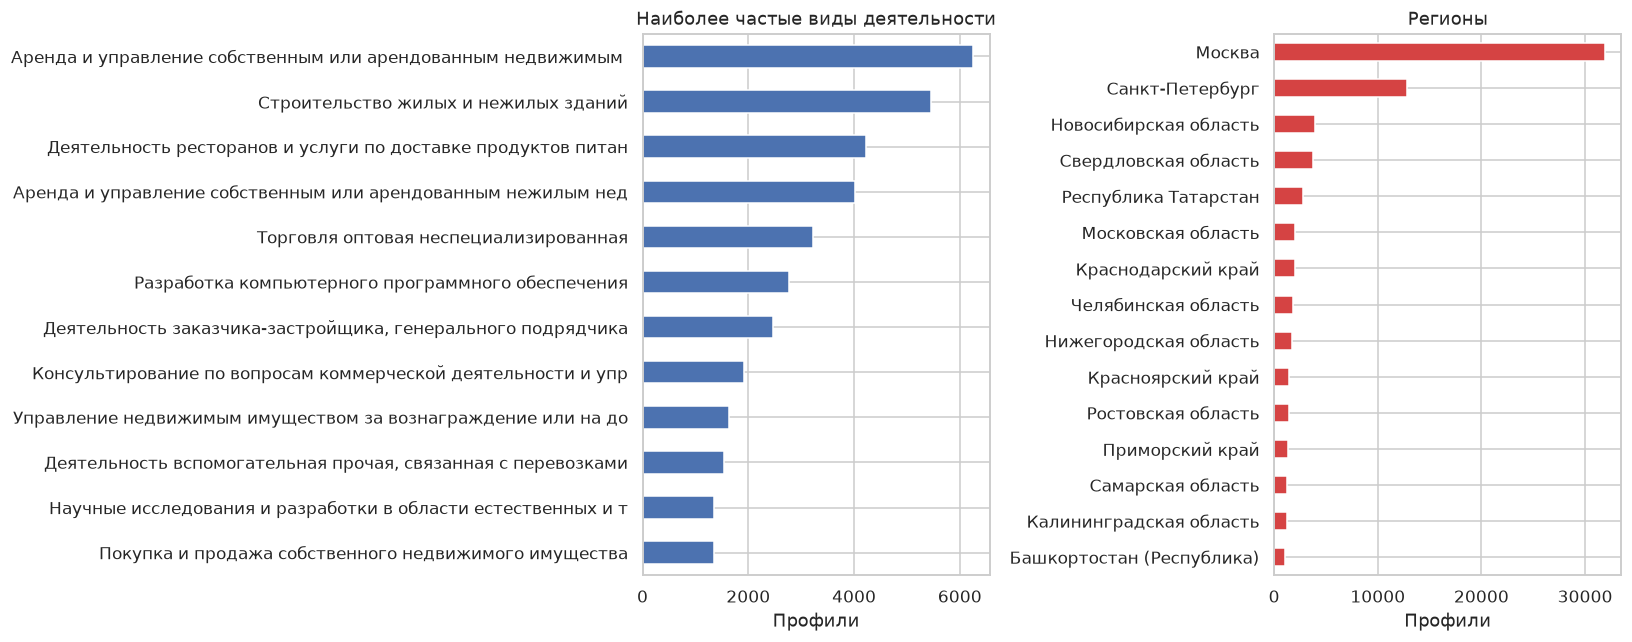

,profiles
CITY,
г. Москва,31655
г. Санкт-Петербург,12679
г. Новосибирск,3857
г. Екатеринбург,3634
г. Казань,2293
г. Челябинск,1570
г. Нижний Новгород,1528
г. Краснодар,1452
г. Красноярск,1421


Названий городов, встречающихся в нескольких регионах: 14


,profiles,clients,median_revenue
okved_2,,,
46,16106,9252,272443482.5
68,15978,5404,14998278.5
41,5964,3017,10232128.5
56,5193,3018,62700969.0
71,4035,1666,2632197.5
62,3492,1944,43786320.0
45,2661,1592,206858290.0
47,2621,1381,39553059.0
70,2545,978,4136344.0


In [10]:
companies["okved_2"] = companies.MAINOKVED_CODE.str.extract(r"^(\d{2})", expand=False)
code_to_name = companies.groupby("MAINOKVED_CODE").MAINOKVED_NAME.nunique()
name_to_code = companies.groupby("MAINOKVED_NAME").MAINOKVED_CODE.nunique()
display(
    pd.Series(
        {
            "invalid_okved_format": int(
                (
                    ~companies.MAINOKVED_CODE.str.fullmatch(r"\d{2}(?:\.\d{1,2}){0,2}").fillna(
                        False
                    )
                ).sum()
            ),
            "codes_with_multiple_names": int(code_to_name.gt(1).sum()),
            "names_with_multiple_codes": int(name_to_code.gt(1).sum()),
        }
    ).to_frame("value")
)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
companies.MAINOKVED_NAME.value_counts().head(12).sort_values().rename(
    index=lambda s: s[:60]
).plot.barh(ax=axes[0])
axes[0].set(title="Наиболее частые виды деятельности", xlabel="Профили", ylabel="")
companies.REGION.value_counts().head(15).sort_values().plot.barh(ax=axes[1], color="#D54343")
axes[1].set(title="Регионы", xlabel="Профили", ylabel="")
plt.tight_layout()
plt.show()
display(companies.CITY.value_counts().head(15).rename("profiles").to_frame())
print(
    "Названий городов, встречающихся в нескольких регионах:",
    int(companies.groupby("CITY").REGION.nunique().gt(1).sum()),
)
display(
    companies.groupby("okved_2")
    .agg(
        profiles=("SYNTHETIC_U", "size"),
        clients=("CL_TYPE", lambda s: s.eq("CLIENT").sum()),
        median_revenue=("revenue_valid", "median"),
    )
    .sort_values("profiles", ascending=False)
    .head(15)
    .round(2)
)

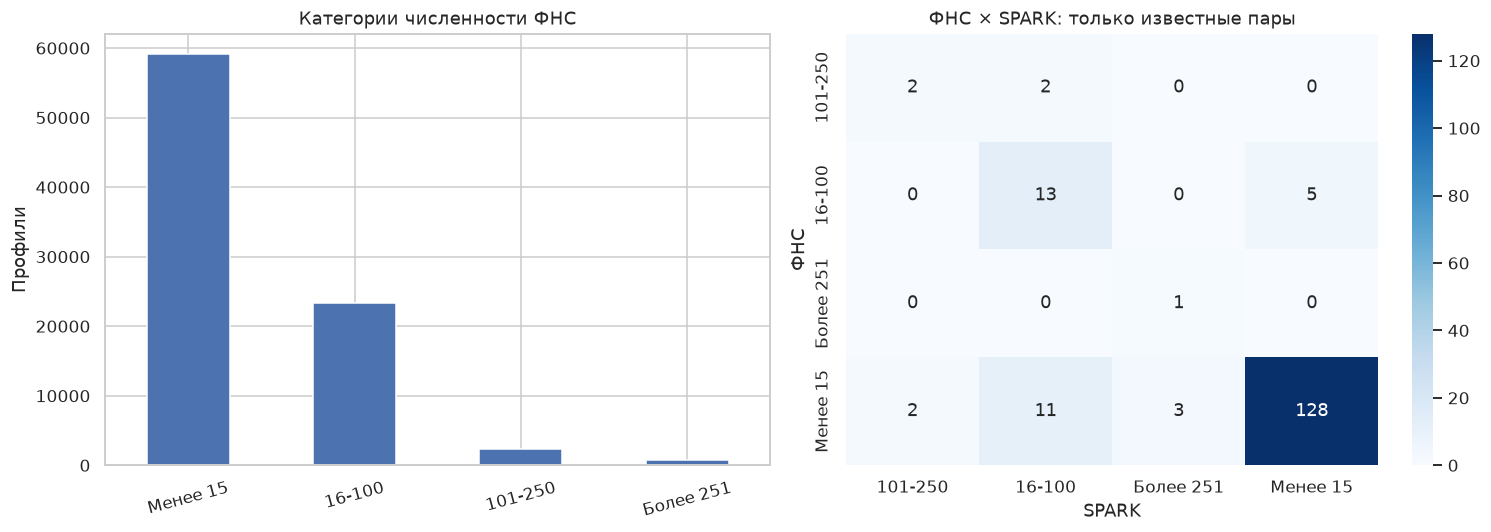

Страны заполнены,False,True
FTS_FLAG,,
0,76943,206
1,224,8140


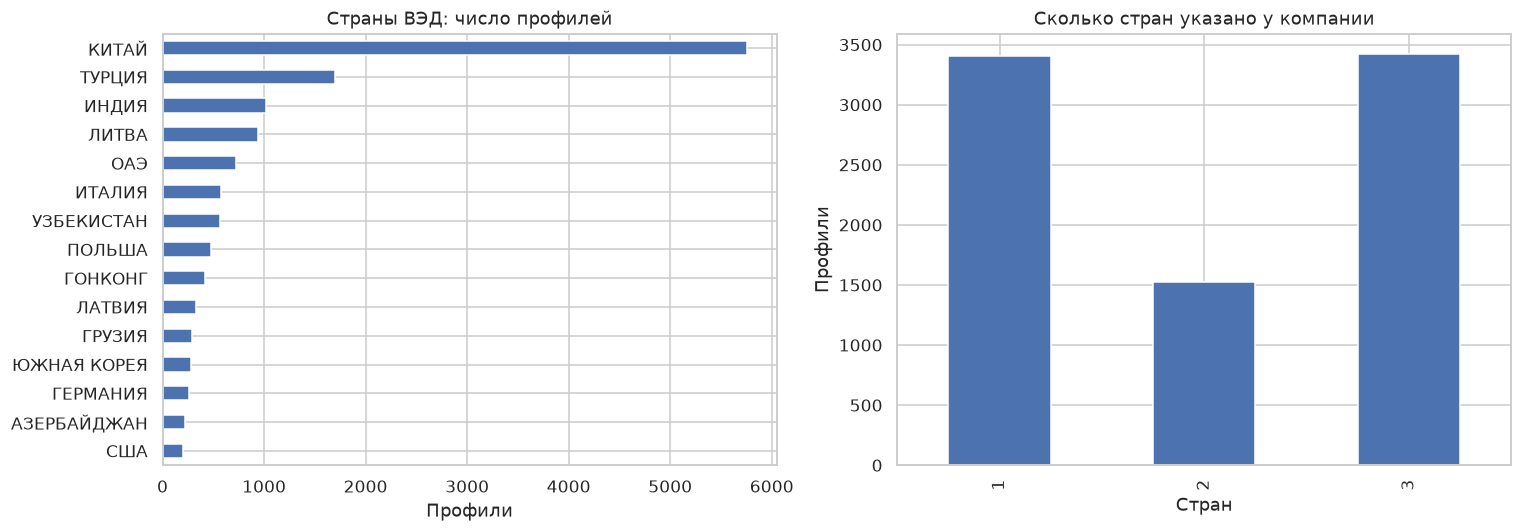

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
companies.AMOUNT_WORKERS_FNS_GRADATION.value_counts().reindex(
    ["Менее 15", "16-100", "101-250", "Более 251"]
).plot.bar(ax=axes[0], rot=15)
axes[0].set(title="Категории численности ФНС", ylabel="Профили", xlabel="")
worker_joint = pd.crosstab(
    companies.AMOUNT_WORKERS_FNS_GRADATION, companies.AMOUNT_WORKERS_SPARK_GRADATION
)
sns.heatmap(worker_joint, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set(title="ФНС × SPARK: только известные пары", xlabel="SPARK", ylabel="ФНС")
plt.tight_layout()
plt.show()
fts_cross = pd.crosstab(
    companies.FTS_FLAG,
    companies.FTS_COUNTRY_NAME.notna(),
    rownames=["FTS_FLAG"],
    colnames=["Страны заполнены"],
)
display(fts_cross)
countries = (
    companies[["SYNTHETIC_U", "FTS_COUNTRY_NAME"]]
    .dropna()
    .assign(country=lambda d: d.FTS_COUNTRY_NAME.str.split(","))
    .explode("country")
)
countries["country"] = countries.country.str.strip()
countries = countries.drop_duplicates(["SYNTHETIC_U", "country"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
countries.country.value_counts().head(15).sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Страны ВЭД: число профилей", xlabel="Профили", ylabel="")
countries.groupby("SYNTHETIC_U").size().value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title="Сколько стран указано у компании", xlabel="Стран", ylabel="Профили")
plt.tight_layout()
plt.show()

Категории штата не дают точную численность. SPARK почти пустой, поэтому совпадения с ФНС на заполненных строках мало говорят о согласованности источников в целом.

Страны ВЭД не раскрывают направление торговли, валюту или долю оборота. Страна в списке сама по себе не означает импорт в её валюте. `CITY` и `REGION` относятся к профилю компании; `CITY_NAME` и `RC_NAME` — к таблице связей физлиц.

Есть 224 профиля с `FTS_FLAG=1` без стран и 206 со странами при `FTS_FLAG=0`. Флаги не исправляем автоматически. В одной строке перечислено максимум три страны; неизвестно, полон ли список.

## 8. Зависимости между признаками


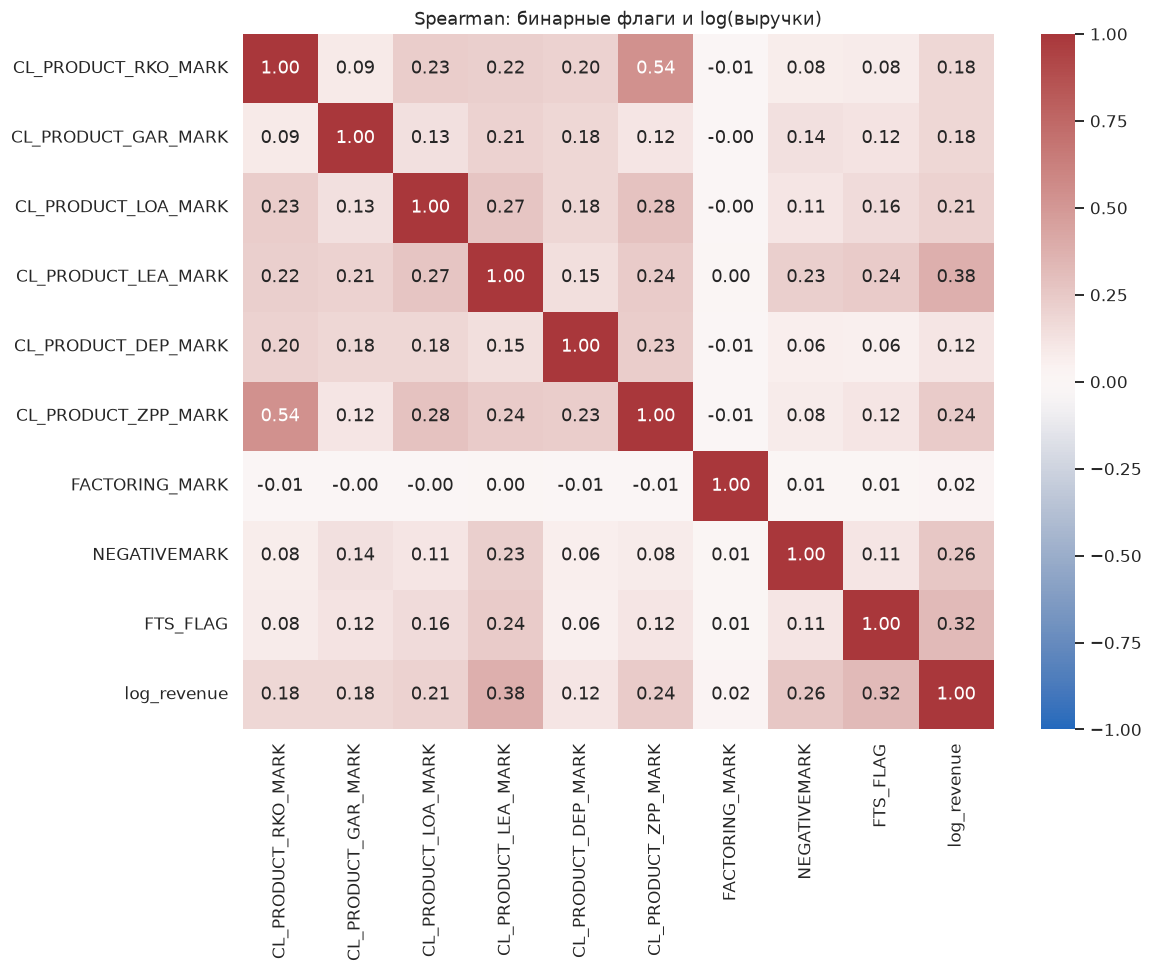

ECO_MARK_LABEL,Бизнес в новой реальности,Оптимизация,Рождение,Стремительный рост
CL_TYPE,,,,
CLIENT,33.22,58.60,5.02,3.16
CLOSE_CLIENT,28.81,66.68,3.44,1.06
PROSPECT,29.02,67.06,3.27,0.65


In [12]:
corr_data = companies[flags].astype(float).assign(log_revenue=np.log10(companies.revenue_valid))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_data.corr(method="spearman"),
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    ax=ax,
)
ax.set_title("Spearman: бинарные флаги и log(выручки)")
plt.tight_layout()
plt.show()
display(
    pd.crosstab(companies.CL_TYPE, companies.ECO_MARK_LABEL, normalize="index").mul(100).round(2)
)

Корреляции показывают совместное изменение признаков, но не причину. Компании одной группы и платёжные контрагенты связаны между собой: при дальнейшем обучении случайное разбиение строк может дать завышенную оценку качества.

## 9. Платежи: единицы, дубликаты и распределения


,parse_error,nonpositive,nonfinite
PAY_AMT,0,0,0
PAY_CNT,0,0,0


Нецелое PAY_CNT: 0
Повторных строк: 1 ; повторных направленных пар: 17


,BENEFICIARY,PAYER,PAY_AMT,PAY_CNT
624257,U_129457,U_428697,641000.0,1
1126759,U_129457,U_428697,632000.0,6
906543,U_13199,U_428697,2674000.0,10
1121000,U_13199,U_428697,1259000.0,2
177784,U_219067,U_428697,3069000.0,9
208957,U_219067,U_428697,1274000.0,8
127686,U_24469,U_428697,1792000.0,1
548649,U_24469,U_428697,31521000.0,8
422580,U_46007,U_428697,6619000.0,19
510502,U_46007,U_428697,4751000.0,1


,PAY_AMT,PAY_CNT
count,1380585.0,1380585.0
mean,40556166.83,17.76
std,1814375335.53,136.31
min,1000.0,1.0
1%,2000.0,1.0
50%,212000.0,5.0
90%,8561000.0,32.0
95%,25599600.0,64.0
99%,234675080.0,219.0
99.9%,6344360704.0,768.0


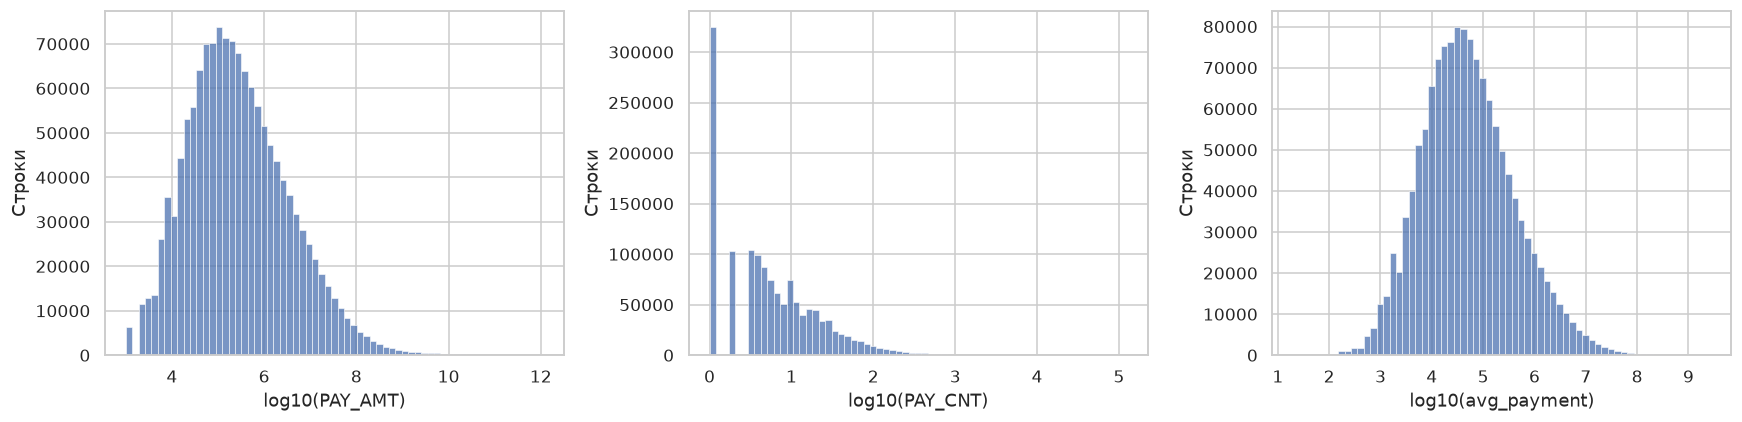

In [13]:
payments = payments_raw.copy()
for col in ["PAY_AMT", "PAY_CNT"]:
    payments[col] = pd.to_numeric(payments[col], errors="coerce")
pay_audit = pd.DataFrame(
    {
        "parse_error": payments[["PAY_AMT", "PAY_CNT"]].isna().sum(),
        "nonpositive": payments[["PAY_AMT", "PAY_CNT"]].le(0).sum(),
        "nonfinite": (~np.isfinite(payments[["PAY_AMT", "PAY_CNT"]])).sum(),
    }
)
display(pay_audit)
print("Нецелое PAY_CNT:", int(payments.PAY_CNT.mod(1).ne(0).sum()))
print(
    "Повторных строк:",
    int(payments.duplicated().sum()),
    "; повторных направленных пар:",
    int(payments.duplicated(["PAYER", "BENEFICIARY"]).sum()),
)
display(
    payments[payments.duplicated(["PAYER", "BENEFICIARY"], keep=False)]
    .sort_values(["PAYER", "BENEFICIARY"])
    .head(40)
)
display(
    payments[["PAY_AMT", "PAY_CNT"]]
    .describe(percentiles=[0.01, 0.5, 0.9, 0.95, 0.99, 0.999])
    .round(2)
)
payments["avg_payment"] = payments.PAY_AMT / payments.PAY_CNT
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["PAY_AMT", "PAY_CNT", "avg_payment"]):
    sns.histplot(np.log10(payments[col]), bins=65, ax=ax)
    ax.set(xlabel=f"log10({col})", ylabel="Строки")
plt.tight_layout()
plt.show()

`PAY_AMT` — сумма в рублях, `PAY_CNT` — число операций. Дат, периода, валюты и назначения платежей нет. Повтор направленной пары не обязательно означает дубль транзакции; отдельно проверяем его связь с неоднозначным ID.

## 10. Самопереводы и неполное покрытие контрагентов


,rows,amount,operations,rows_pct,amount_pct,operations_pct
self_transfer,,,,,,
False,1353179,10269508255000.0,21256928,98.015,18.341,86.707
True,27406,45721727331000.0,3258858,1.985,81.659,13.293


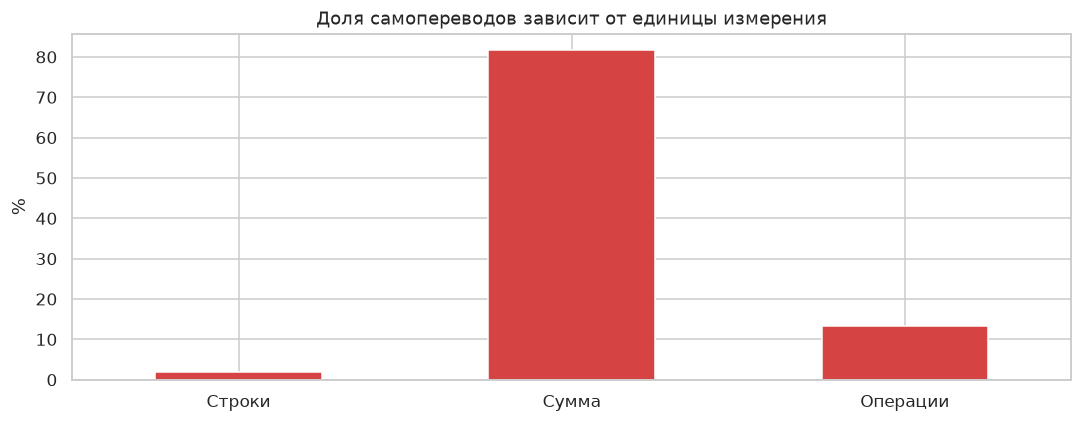

rows            amount  operations  rows_pct  \
payer_known recipient_known                                                   
False       False                76      4765327000.0         925      0.01   
            True             582228   3814730902000.0     8280309     42.17   
True        False            408962   3488849794000.0     6968386     29.62   
            True             389319  48682889563000.0     9266166      28.2   

                             amount_pct  
payer_known recipient_known              
False       False                  0.01  
            True                   6.81  
True        False                  6.23  
            True                  86.95

,nodes
payment_nodes,178159
nodes_without_unambiguous_profile,114553
profiles_without_payments,21907


In [14]:
payments["self_transfer"] = payments.PAYER.eq(payments.BENEFICIARY)
self_stats = payments.groupby("self_transfer").agg(
    rows=("PAY_AMT", "size"), amount=("PAY_AMT", "sum"), operations=("PAY_CNT", "sum")
)
for col in ["rows", "amount", "operations"]:
    self_stats[col + "_pct"] = self_stats[col] / self_stats[col].sum() * 100
display(self_stats.round(3))
fig, ax = plt.subplots(figsize=(10, 4))
self_stats.loc[True, ["rows_pct", "amount_pct", "operations_pct"]].rename(
    index={"rows_pct": "Строки", "amount_pct": "Сумма", "operations_pct": "Операции"}
).plot.bar(ax=ax, rot=0, color="#D54343")
ax.set(title="Доля самопереводов зависит от единицы измерения", ylabel="%")
plt.tight_layout()
plt.show()
payments["payer_known"] = payments.PAYER.isin(ids)
payments["recipient_known"] = payments.BENEFICIARY.isin(ids)
coverage = payments.groupby(["payer_known", "recipient_known"]).agg(
    rows=("PAY_AMT", "size"), amount=("PAY_AMT", "sum"), operations=("PAY_CNT", "sum")
)
coverage["rows_pct"] = coverage.rows / len(payments) * 100
coverage["amount_pct"] = coverage.amount / payments.PAY_AMT.sum() * 100
display(coverage.round(2))
all_nodes = set(payments.PAYER) | set(payments.BENEFICIARY)
display(
    pd.Series(
        {
            "payment_nodes": len(all_nodes),
            "nodes_without_unambiguous_profile": len(all_nodes - ids),
            "profiles_without_payments": len(ids - all_nodes),
        }
    ).to_frame("nodes")
)

Самопереводы — отдельный тип связи, а не торговля с поставщиком. Их доля суммы около 82%, но доля операций и доля строк существенно отличаются. В конспекте созвона прозвучало около 3% операций; по файлу это не воспроизводится. Расчёты основаны на CSV; для каждой доли указан знаменатель.

Отсутствие профиля контрагента не означает ошибку платежа или отсутствие риска. Такой узел сохраняется в графе без профиля; его отрасль, регион и размер остаются неизвестными.

,excluded,share_pct
rows,1.530000e+02,0.0111
amount,9.764060e+09,0.0174
operations,2.751000e+03,0.0112


Повторы направленных пар без неоднозначного ID: 0


,rows,amount,operations,rows_pct,amount_pct,operations_pct
flow_type,,,,,,
внутри известной группы,34356,1201243362000.0,772689,2.49,2.15,3.15
между известными группами,327557,1759918870000.0,5234619,23.73,3.14,21.35
неполное покрытие групп,991113,7298581963000.0,15246869,71.8,13.04,62.2
самоперевод,27406,45721727331000.0,3258858,1.99,81.67,13.29


,top_pct,amount_share_pct
0,0.1,28.17
1,1.0,59.67
2,5.0,83.76
3,10.0,91.62


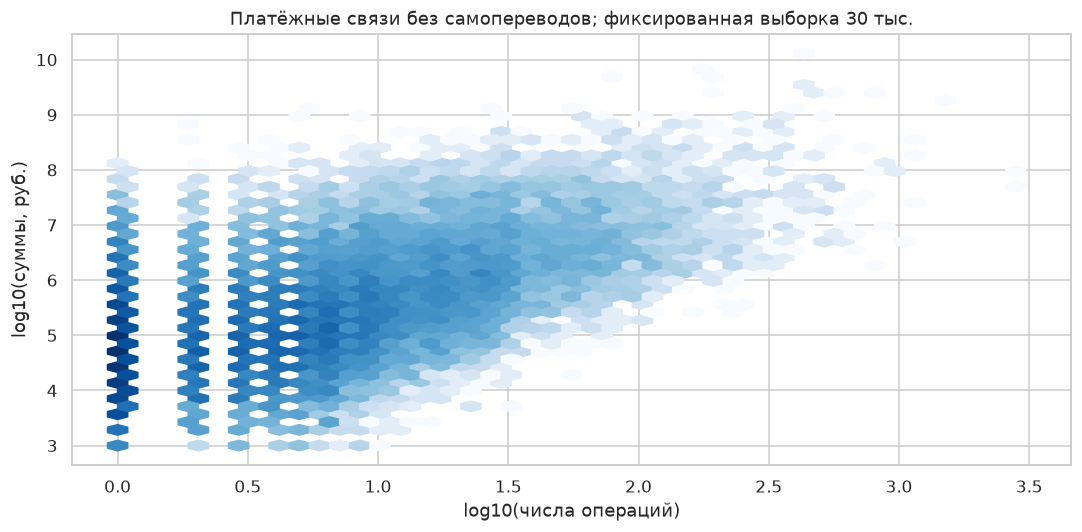

In [15]:
# Неоднозначный ID исключён из связей с группами; исходные суммы приведены выше.
excluded = payments[payment_ambiguous]
display(
    pd.DataFrame(
        {
            "excluded": [len(excluded), excluded.PAY_AMT.sum(), excluded.PAY_CNT.sum()],
            "share_pct": [
                len(excluded) / len(payments) * 100,
                excluded.PAY_AMT.sum() / payments.PAY_AMT.sum() * 100,
                excluded.PAY_CNT.sum() / payments.PAY_CNT.sum() * 100,
            ],
        },
        index=["rows", "amount", "operations"],
    ).round(4)
)
print(
    "Повторы направленных пар без неоднозначного ID:",
    int(payments.loc[~payment_ambiguous].duplicated(["PAYER", "BENEFICIARY"]).sum()),
)
pay = payments[~payment_ambiguous].copy()
profile_group = companies.set_index("SYNTHETIC_U").GROUP_ID
pay["payer_group"] = pay.PAYER.map(profile_group)
pay["recipient_group"] = pay.BENEFICIARY.map(profile_group)
pay["flow_type"] = np.select(
    [
        pay.self_transfer.to_numpy(dtype=bool),
        (
            pay.payer_group.notna()
            & pay.recipient_group.notna()
            & pay.payer_group.eq(pay.recipient_group)
        ).to_numpy(dtype=bool),
        (pay.payer_group.notna() & pay.recipient_group.notna()).to_numpy(dtype=bool),
    ],
    ["самоперевод", "внутри известной группы", "между известными группами"],
    default="неполное покрытие групп",
)
flows = pay.groupby("flow_type").agg(
    rows=("PAY_AMT", "size"), amount=("PAY_AMT", "sum"), operations=("PAY_CNT", "sum")
)
for col in ["rows", "amount", "operations"]:
    flows[col + "_pct"] = flows[col] / flows[col].sum() * 100
display(flows.round(2))
external = pay[~pay.self_transfer].copy()
positive = external.PAY_AMT.sort_values(ascending=False).reset_index(drop=True)
display(
    pd.DataFrame(
        [
            {
                "top_pct": k,
                "amount_share_pct": positive.iloc[
                    : max(1, int(np.ceil(len(positive) * k / 100)))
                ].sum()
                / positive.sum()
                * 100,
            }
            for k in [0.1, 1, 5, 10]
        ]
    ).round(2)
)
sample = external.sample(min(30000, len(external)), random_state=SEED)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hexbin(
    np.log10(sample.PAY_CNT),
    np.log10(sample.PAY_AMT),
    gridsize=45,
    mincnt=1,
    bins="log",
    cmap="Blues",
)
ax.set(
    xlabel="log10(числа операций)",
    ylabel="log10(суммы, руб.)",
    title="Платёжные связи без самопереводов; фиксированная выборка 30 тыс.",
)
plt.tight_layout()
plt.show()

Самопереводы и переводы внутри группы выделены в разные категории. Сопоставление по `GROUP_ID` возможно только при наличии однозначных профилей обеих сторон. Для остальных пар принадлежность к одной группе неизвестна. Сумма исходящих платежей не равна себестоимости, входящих — выручке: назначения платежей и сопоставимого периода нет.

## 11. Платёжный граф и концентрация зависимостей

,value
nodes,1.773040e+05
directed_edges,1.353026e+06
weak_components,1.980000e+02
largest_component_nodes,1.768580e+05
largest_component_pct,9.974845e+01


,out_partners,in_partners,largest_out_share,largest_in_share
count,177304.000,177304.000,161826.0,112272.0
mean,7.631,7.631,0.747,0.755
std,17.788,76.721,0.25,0.274
min,0.000,0.000,0.027,0.007
50%,3.000,1.000,0.811,0.876
90%,18.000,13.000,1.0,1.0
99%,71.000,106.000,1.0,1.0
max,1571.000,19782.000,1.0,1.0


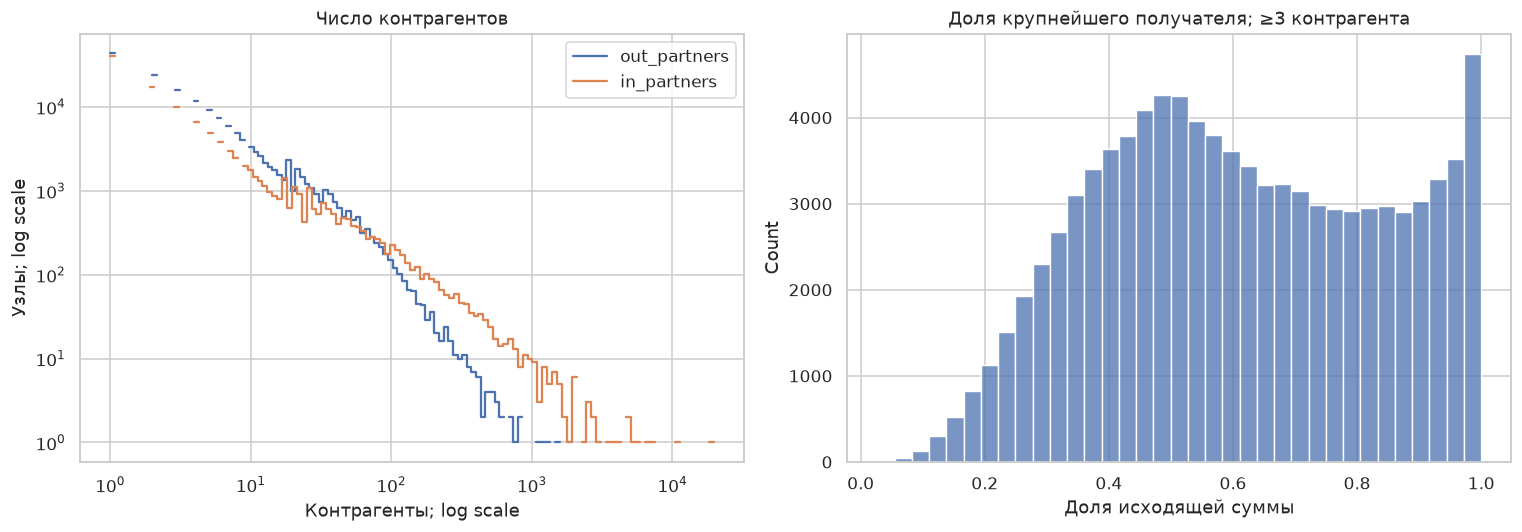

,out_partners,out_amount,largest_out,in_partners,in_amount,largest_in,largest_out_share,largest_in_share,profile_known
PAYER,,,,,,,,,
U_235754,72.0,82883760000.0,81841503000.0,2.0,253000.0,247000.0,0.987,0.976,False
U_47078,1135.0,32141815000.0,860588000.0,738.0,2034333000.0,986296000.0,0.027,0.485,True
U_56949,44.0,30349653000.0,13606775000.0,10.0,530369000.0,200456000.0,0.448,0.378,True
U_66319,43.0,29686211000.0,23897809000.0,10.0,166423000.0,92638000.0,0.805,0.557,True
U_123123,24.0,29436057000.0,14175279000.0,47.0,3791300000.0,1044607000.0,0.482,0.276,True
U_258131,386.0,28192946000.0,16125615000.0,1442.0,6435970000.0,2616100000.0,0.572,0.406,True
U_3263,417.0,27029434000.0,6384169000.0,227.0,3915219000.0,930856000.0,0.236,0.238,True
U_32124,13.0,26875180000.0,25476609000.0,4.0,11679109000.0,11579164000.0,0.948,0.991,True
U_26379,42.0,22556514000.0,9588908000.0,19.0,17069980000.0,6023433000.0,0.425,0.353,False


In [16]:
edges = external.groupby(["PAYER", "BENEFICIARY"], as_index=False).agg(
    amount=("PAY_AMT", "sum"), operations=("PAY_CNT", "sum")
)
node_index = pd.Index(sorted(set(edges.PAYER) | set(edges.BENEFICIARY)))
src = node_index.get_indexer(edges.PAYER)
dst = node_index.get_indexer(edges.BENEFICIARY)
adjacency = coo_matrix(
    (np.ones(len(edges), dtype=np.int8), (src, dst)), shape=(len(node_index), len(node_index))
).tocsr()
n_components, component_labels = connected_components(adjacency, directed=True, connection="weak")
component_sizes = pd.Series(component_labels).value_counts()
out_stats = edges.groupby("PAYER").agg(
    out_partners=("BENEFICIARY", "nunique"),
    out_amount=("amount", "sum"),
    largest_out=("amount", "max"),
)
in_stats = edges.groupby("BENEFICIARY").agg(
    in_partners=("PAYER", "nunique"), in_amount=("amount", "sum"), largest_in=("amount", "max")
)
node_stats = out_stats.join(in_stats, how="outer").fillna(0)
node_stats["largest_out_share"] = node_stats.largest_out.div(
    node_stats.out_amount.where(node_stats.out_amount.gt(0))
)
node_stats["largest_in_share"] = node_stats.largest_in.div(
    node_stats.in_amount.where(node_stats.in_amount.gt(0))
)
node_stats["profile_known"] = node_stats.index.isin(ids)
display(
    pd.Series(
        {
            "nodes": len(node_index),
            "directed_edges": len(edges),
            "weak_components": n_components,
            "largest_component_nodes": component_sizes.iloc[0],
            "largest_component_pct": component_sizes.iloc[0] / len(node_index) * 100,
        }
    ).to_frame("value")
)
display(
    node_stats[["out_partners", "in_partners", "largest_out_share", "largest_in_share"]]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(3)
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col in ["out_partners", "in_partners"]:
    sns.histplot(
        node_stats.loc[node_stats[col] > 0, col],
        log_scale=(True, True),
        element="step",
        fill=False,
        label=col,
        ax=axes[0],
    )
axes[0].legend()
axes[0].set(title="Число контрагентов", xlabel="Контрагенты; log scale", ylabel="Узлы; log scale")
sns.histplot(node_stats.loc[node_stats.out_partners >= 3, "largest_out_share"], bins=35, ax=axes[1])
axes[1].set(title="Доля крупнейшего получателя; ≥3 контрагента", xlabel="Доля исходящей суммы")
plt.tight_layout()
plt.show()
display(node_stats.sort_values("out_amount", ascending=False).head(10).round(3))

Почти все платёжные узлы входят в одну большую компоненту. Она описывает связанность переводами, а не общую группу владения.

Доля крупнейшего получателя показывает концентрацию платежей. Без назначения платежа нельзя назвать его поставщиком, а высокую долю — доказанной зависимостью бизнеса.

## 12. Покрытие связей физлиц


,value
people,11120.000000
companies,12307.000000
known_link_rows_pct,36.990571
people_with_multiple_companies,969.000000
people_with_multiple_known_groups,46.000000
companies_with_multiple_people,192.000000
duplicate_pairs,0.000000


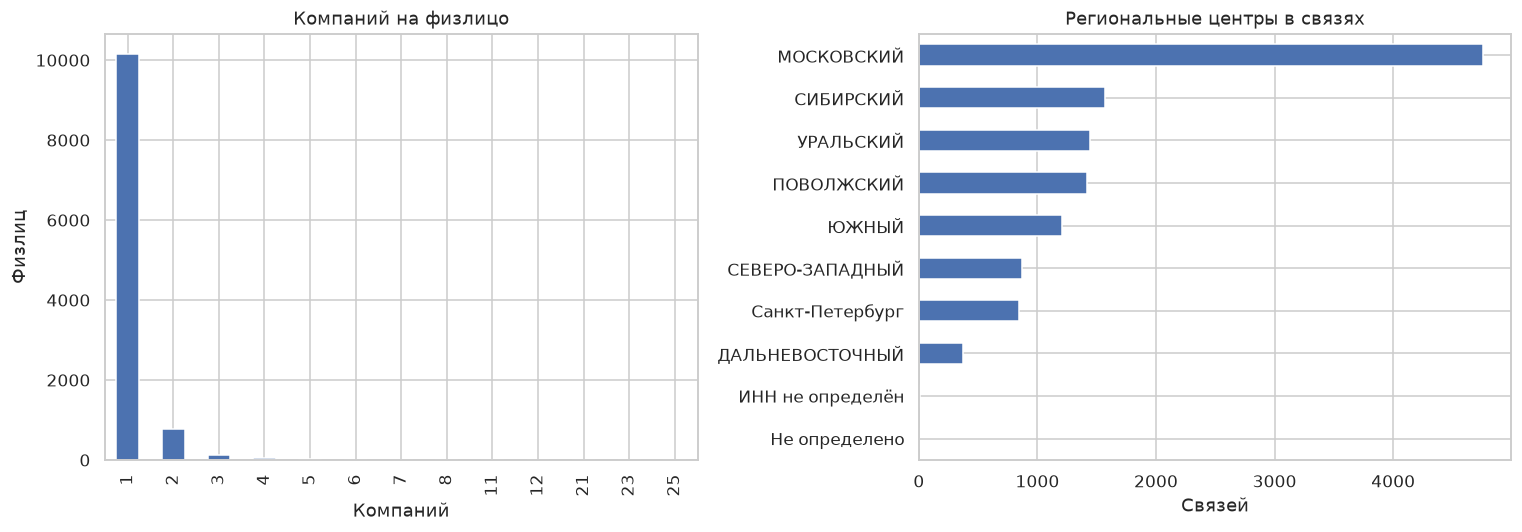

,companies,known_profiles,known_groups
SYNTHETIC_F,,,
F_59737,25,4,4
F_88745,23,1,1
F_47885,21,1,1
F_37791,12,0,0
F_76401,11,1,1
F_9000,8,0,0
F_83639,8,4,1
F_11145,7,2,2
F_23818,7,1,1


,links
CITY_NAME,
Москва,3275
Санкт-Петербург,846
Новосибирск,558
Екатеринбург,495
Краснодар,431
Казань,361
Челябинск,283
Красноярск,260
Ростов-на-Дону,250


,people_with_multiple_values
CITY_NAME,250
RC_NAME,116


In [17]:
links = links_raw[~link_ambiguous].copy()
links["profile_known"] = links.SYNTHETIC_U.isin(ids)
links["group"] = links.SYNTHETIC_U.map(profile_group)
person_degree = links.groupby("SYNTHETIC_F").agg(
    companies=("SYNTHETIC_U", "nunique"),
    known_profiles=("profile_known", "sum"),
    known_groups=("group", "nunique"),
)
company_degree = links.groupby("SYNTHETIC_U").SYNTHETIC_F.nunique()
display(
    pd.Series(
        {
            "people": links.SYNTHETIC_F.nunique(),
            "companies": links.SYNTHETIC_U.nunique(),
            "known_link_rows_pct": links.profile_known.mean() * 100,
            "people_with_multiple_companies": person_degree.companies.gt(1).sum(),
            "people_with_multiple_known_groups": person_degree.known_groups.gt(1).sum(),
            "companies_with_multiple_people": company_degree.gt(1).sum(),
            "duplicate_pairs": links.duplicated(["SYNTHETIC_F", "SYNTHETIC_U"]).sum(),
        }
    ).to_frame("value")
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
person_degree.companies.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title="Компаний на физлицо", xlabel="Компаний", ylabel="Физлиц")
links.RC_NAME.value_counts().sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Региональные центры в связях", xlabel="Связей", ylabel="")
plt.tight_layout()
plt.show()
display(person_degree.sort_values("companies", ascending=False).head(15))
display(links.CITY_NAME.value_counts(dropna=False).head(15).rename("links").to_frame())
person_geography = links.groupby("SYNTHETIC_F")[["CITY_NAME", "RC_NAME"]].nunique()
display(person_geography.gt(1).sum().rename("people_with_multiple_values").to_frame())

Одно физлицо может связывать несколько компаний и известных групп. Таблица не раскрывает должность и долю владения; по ней нельзя автоматически объединить группы. Отсутствие строки также не доказывает отсутствие связи.

## 13. Покрытие контекста компании


In [18]:
features = companies.set_index("SYNTHETIC_U")[
    ["CL_TYPE", "GROUP_ID", "okved_2", "revenue_valid", "FTS_FLAG"]
].copy()
features["has_revenue"] = features.revenue_valid.notna()
features["has_payment"] = features.index.isin(all_nodes)
features["has_person_link"] = features.index.isin(set(links.SYNTHETIC_U))
features["has_countries"] = features.index.isin(set(countries.SYNTHETIC_U))
display(
    features.groupby("CL_TYPE")[["has_revenue", "has_payment", "has_person_link", "has_countries"]]
    .mean()
    .mul(100)
    .round(2)
)
client_context = features[features.CL_TYPE.eq("CLIENT")]
print("Клиенты без валидной выручки:", int((~client_context.has_revenue).sum()))
print("Клиенты без платёжного узла:", int((~client_context.has_payment).sum()))
print("Клиенты без связей физлиц:", int((~client_context.has_person_link).sum()))

,has_revenue,has_payment,has_person_link,has_countries
CL_TYPE,,,,
CLIENT,99.48,91.08,9.53,12.58
CLOSE_CLIENT,99.33,74.00,7.26,16.72
PROSPECT,99.09,55.35,0.06,5.23


Клиенты без валидной выручки: 220
Клиенты без платёжного узла: 3744
Клиенты без связей физлиц: 37969


Заполненный профиль всё равно не содержит условий договоров, хеджирования, себестоимости и валютных долей. Ниже проверяем ещё один пробел: **какая часть платежей конкретной компании приходится на контрагентов с известным профилем**.

Самопереводы исключены, внутригрупповые переводы оставлены. Для каждого направления учитываются только компании с наблюдаемыми платежами в этом направлении. Отсутствие платежей не превращается в нулевое покрытие.


companies  median_coverage_pct  below_half  \
CL_TYPE      direction                                               
CLIENT       Входящие       33334                46.77       17240   
             Исходящие      35354                48.48       18027   
CLOSE_CLIENT Входящие        3938                 48.3        2014   
             Исходящие       4550                43.75        2392   
PROSPECT     Входящие       12968                51.49        6377   
             Исходящие      18227                26.17       10580   

                        weighted_coverage_pct  
CL_TYPE      direction                         
CLIENT       Входящие                   43.32  
             Исходящие                  45.35  
CLOSE_CLIENT Входящие                   44.84  
             Исходящие                  51.01  
PROSPECT     Входящие                   47.66  
             Исходящие                  50.59

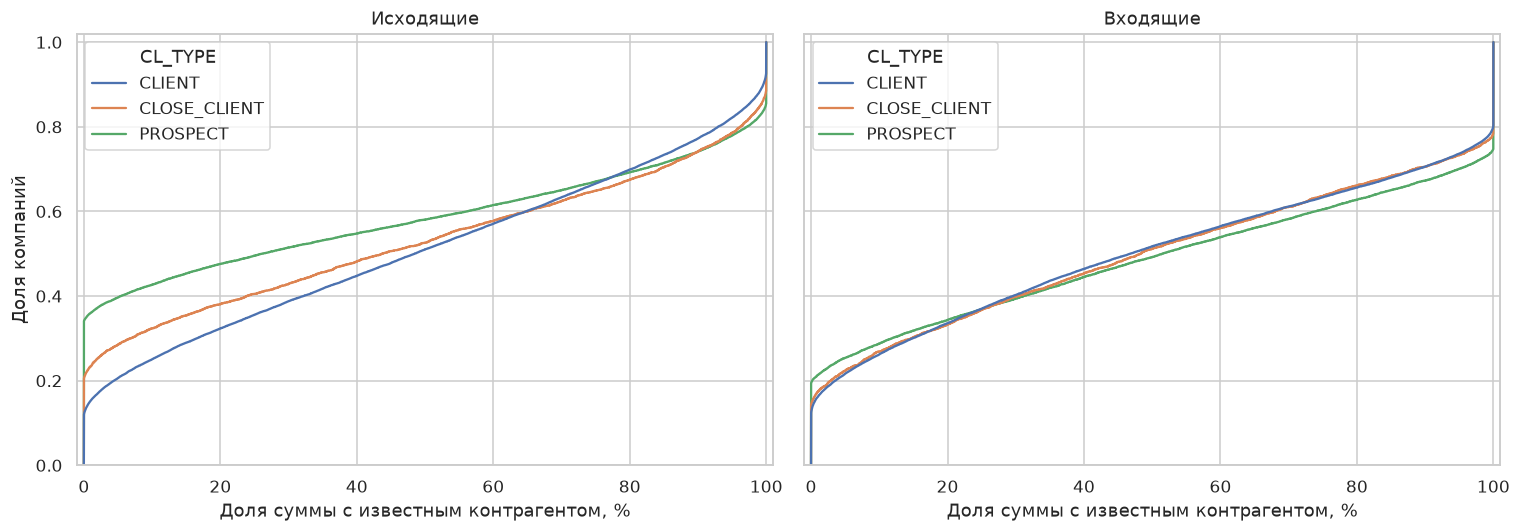

,company,amount,known_amount,partners,CL_TYPE,known_share_pct,direction
47024,U_47078,32141815000.0,14518974000.0,1135,CLIENT,45.17,Исходящие
26846,U_258131,28192946000.0,1162275000.0,386,CLIENT,4.12,Исходящие
33734,U_32124,26875180000.0,1231355000.0,13,CLIENT,4.58,Исходящие
74481,U_197411,26610332000.0,7799600000.0,205,CLIENT,29.31,Входящие
58667,U_102920,25323243000.0,8340184000.0,178,CLIENT,32.93,Входящие
57784,U_98244,22011124000.0,222459000.0,12,CLIENT,1.01,Исходящие
10466,U_155617,20241646000.0,98047000.0,15,CLIENT,0.48,Исходящие
55489,U_86785,19953567000.0,7189280000.0,51,CLIENT,36.03,Исходящие
49236,U_57162,16904175000.0,90911000.0,30,CLIENT,0.54,Исходящие
68126,U_15776,16769298000.0,5439354000.0,229,CLIENT,32.44,Входящие


In [19]:
payment_context = []
for direction, company_col, partner_col in [
    ("Исходящие", "PAYER", "BENEFICIARY"),
    ("Входящие", "BENEFICIARY", "PAYER"),
]:
    amounts = external.assign(
        known_amount=external.PAY_AMT.where(external[partner_col].isin(ids), 0)
    ).groupby(company_col).agg(
        amount=("PAY_AMT", "sum"),
        known_amount=("known_amount", "sum"),
        partners=(partner_col, "nunique"),
    )
    amounts = amounts.join(features.CL_TYPE, how="inner")
    amounts["known_share_pct"] = amounts.known_amount / amounts.amount * 100
    amounts["direction"] = direction
    amounts.index.name = "company"
    payment_context.append(amounts.reset_index())
payment_context = pd.concat(payment_context, ignore_index=True)
assert payment_context.known_share_pct.between(0, 100).all()
assert not payment_context.duplicated(["company", "direction"]).any()

context_summary = payment_context.assign(
    below_half=payment_context.known_share_pct.lt(50)
).groupby(["CL_TYPE", "direction"]).agg(
    companies=("company", "size"),
    amount=("amount", "sum"),
    known_amount=("known_amount", "sum"),
    median_coverage_pct=("known_share_pct", "median"),
    below_half=("below_half", "sum"),
)
context_summary["weighted_coverage_pct"] = (
    context_summary.known_amount / context_summary.amount * 100
)
display(context_summary.drop(columns=["amount", "known_amount"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for direction, ax in zip(["Исходящие", "Входящие"], axes):
    sns.ecdfplot(
        data=payment_context[payment_context.direction.eq(direction)],
        x="known_share_pct", hue="CL_TYPE", ax=ax,
    )
    ax.set(title=direction, xlabel="Доля суммы с известным контрагентом, %",
           ylabel="Доля компаний", xlim=(-1, 101), ylim=(0, 1.02))
plt.tight_layout()
plt.show()

display(payment_context.loc[
    payment_context.CL_TYPE.eq("CLIENT")
    & payment_context.partners.ge(3)
    & payment_context.known_share_pct.lt(50)
].sort_values("amount", ascending=False).head(10).round(2))


У `CLIENT` известные контрагенты покрывают **45,35% исходящей и 43,32% входящей суммы** без самопереводов. Покрытие ниже половины у 18 027 из 35 354 клиентов с исходящими платежами и у 17 240 из 33 334 с входящими.

Среднее по сумме и медиана по компаниям отвечают на разные вопросы: крупные переводы могут скрывать пробелы у отдельных клиентов. Под графиком показаны десять крупнейших по сумме направлений с покрытием ниже 50% и хотя бы тремя контрагентами. Это пробелы в данных, а не рейтинг риска.


## 14. Отраслевые потоки и округление сумм

Срез включает связи с известной отраслью обеих сторон и исключает самопереводы. Он не представляет весь рынок: покрытие контрагентов рассчитано отдельно.

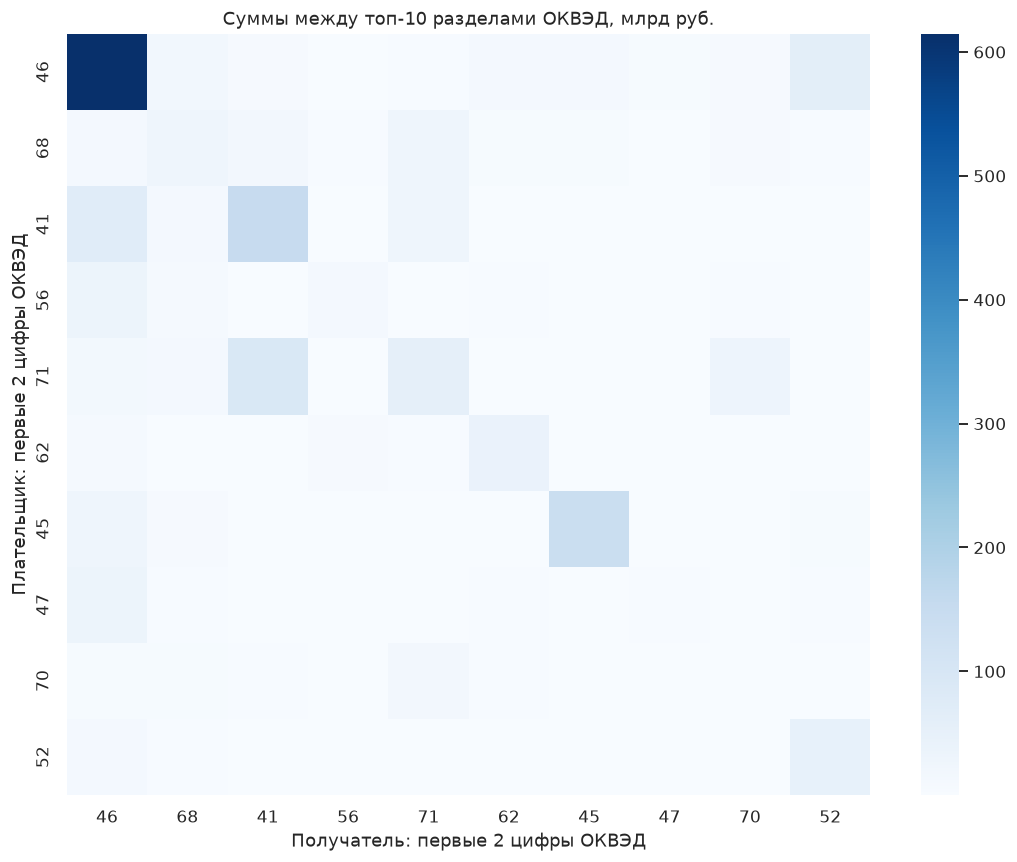

,value
amount_multiple_of_1000_pct,100.0000
amount_count_spearman_all,0.5406
amount_count_spearman_external,0.5269


In [20]:
sector = companies.set_index("SYNTHETIC_U").okved_2
sector_flows = edges.assign(
    payer_sector=edges.PAYER.map(sector), recipient_sector=edges.BENEFICIARY.map(sector)
).dropna(subset=["payer_sector", "recipient_sector"])
top_sectors = companies.okved_2.value_counts().head(10).index
matrix = (
    sector_flows[
        sector_flows.payer_sector.isin(top_sectors)
        & sector_flows.recipient_sector.isin(top_sectors)
    ]
    .pivot_table(
        index="payer_sector",
        columns="recipient_sector",
        values="amount",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(index=top_sectors, columns=top_sectors, fill_value=0)
)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matrix.astype(float) / 1e9, cmap="Blues", ax=ax)
ax.set(
    title="Суммы между топ-10 разделами ОКВЭД, млрд руб.",
    xlabel="Получатель: первые 2 цифры ОКВЭД",
    ylabel="Плательщик: первые 2 цифры ОКВЭД",
)
plt.tight_layout()
plt.show()
display(
    pd.Series(
        {
            "amount_multiple_of_1000_pct": payments.PAY_AMT.mod(1000).eq(0).mean() * 100,
            "amount_count_spearman_all": payments[["PAY_AMT", "PAY_CNT"]]
            .corr(method="spearman")
            .iloc[0, 1],
            "amount_count_spearman_external": external[["PAY_AMT", "PAY_CNT"]]
            .corr(method="spearman")
            .iloc[0, 1],
        }
    )
    .to_frame("value")
    .round(4)
)

Все суммы кратны 1000 рублям. Это похоже на округление при подготовке выгрузки; точность исходных операций по нему не восстановить. `PAY_AMT/PAY_CNT` — средний размер операции, не цена товара.

## 15. Аналитические PDF: текстовый слой и OCR

Для каждой страницы проверены текстовый слой, объём распознанного текста и уверенность OCR. Использован Tesseract: 180 dpi, `rus+eng`, PSM 3. Confidence — внутренняя оценка распознавания, **не доля правильных слов**.

Готовый OCR читается из `data/pdf_ocr.json`. Если PDF изменятся, пересоздать его из корня проекта:

```bash
.venv/bin/python eda/prepare_pdf.py
```

Для повторного OCR нужен Tesseract с русским и английским языками; на macOS — `brew install tesseract tesseract-lang`.


In [21]:
ocr = json.loads((DATA / "pdf_ocr.json").read_text())
# OCR должен соответствовать тем PDF, по которым считаются результаты.
for document in ocr["documents"]:
    pdf_bytes = (DATA / "reports" / document["document"]).read_bytes()
    assert hashlib.sha256(pdf_bytes).hexdigest() == document["sha256"]
pages = pd.DataFrame(ocr["pages"])
documents = pd.DataFrame(ocr["documents"])
assert not pages.duplicated(["document", "page"]).any()
assert not pages.text.str.contains("\t").any(), "В OCR попала служебная TSV-разметка"
assert len(pages) == documents.pages.sum()
pages["chars"] = pages.text.str.len()
pages["digit_share"] = pages.text.map(lambda s: sum(c.isdigit() for c in s) / max(1, len(s)))
pages["cyrillic_share"] = pages.text.map(
    lambda s: len(re.findall("[А-Яа-яЁё]", s)) / max(1, len(s))
)
pages["latin_share"] = pages.text.map(lambda s: len(re.findall("[A-Za-z]", s)) / max(1, len(s)))
pages["numeric_tokens"] = pages.text.str.count(r"\d+(?:[,.]\d+)?")
pdf_summary = documents[["document", "pages", "size_bytes", "sha256"]].merge(
    pages.groupby("document").agg(
        native_chars=("native_chars", "sum"),
        ocr_chars=("chars", "sum"),
        ocr_words=("ocr_words", "sum"),
        confidence=("ocr_confidence", "mean"),
        low_confidence_share=("low_confidence_share", "mean"),
        digit_share=("digit_share", "mean"),
    ),
    on="document",
    validate="one_to_one",
)
pdf_summary["MB"] = pdf_summary.size_bytes / 1e6
display(pdf_summary.drop(columns=["sha256", "size_bytes"]).round(3))
print("Всего страниц:", len(pages), "; без текстового слоя:", int(pages.native_chars.eq(0).sum()))
print(
    "С пустым OCR:",
    int(pages.chars.eq(0).sum()),
    "; точных повторов отрисованной страницы:",
    int(pages.render_sha256.duplicated().sum()),
)
display(pages[pages.render_sha256.duplicated(keep=False)][["document", "page", "render_sha256"]])


,document,pages,native_chars,ocr_chars,ocr_words,confidence,low_confidence_share,digit_share,MB
0,ALFA-7M26.pdf,4,0,12482,1848,92.091,0.035,0.097,6.459
1,ALFA-Macro_Insights-Policy_Rate_11Sep.pdf,4,0,12083,1784,88.481,0.079,0.118,6.343
2,ALFA-consumption.pdf,4,0,13310,2002,89.125,0.077,0.047,6.658
3,ALFA-macro_stat1H26.pdf,5,0,17644,2788,90.385,0.061,0.102,6.100
4,ALFA_Russian_Steels_1К21PreviewUpdate_15Apr2021.pdf,4,0,14593,2212,92.030,0.030,0.127,6.968
5,FI_Strategy_3Q26_22072026.pdf,27,0,53799,8046,88.575,0.086,0.067,34.890
6,Gold_digest_August26.pdf,8,0,14709,2122,90.875,0.042,0.061,8.613
7,Inflation_tracker_02.pdf,3,0,8556,1298,85.292,0.130,0.059,3.386
8,Бонд_Бриф_14092026.pdf,5,0,12006,1674,92.247,0.043,0.073,7.464


Всего страниц: 64 ; без текстового слоя: 64
С пустым OCR: 0 ; точных повторов отрисованной страницы: 3


,document,page,render_sha256
3,ALFA-7M26.pdf,4,7bcba027c7fed2cd477a45f8e0c775ce2ad5a879c7237707d68082948413d354
7,ALFA-Macro_Insights-Policy_Rate_11Sep.pdf,4,7bcba027c7fed2cd477a45f8e0c775ce2ad5a879c7237707d68082948413d354
11,ALFA-consumption.pdf,4,7bcba027c7fed2cd477a45f8e0c775ce2ad5a879c7237707d68082948413d354
20,ALFA_Russian_Steels_1К21PreviewUpdate_15Apr2021.pdf,4,7bcba027c7fed2cd477a45f8e0c775ce2ad5a879c7237707d68082948413d354


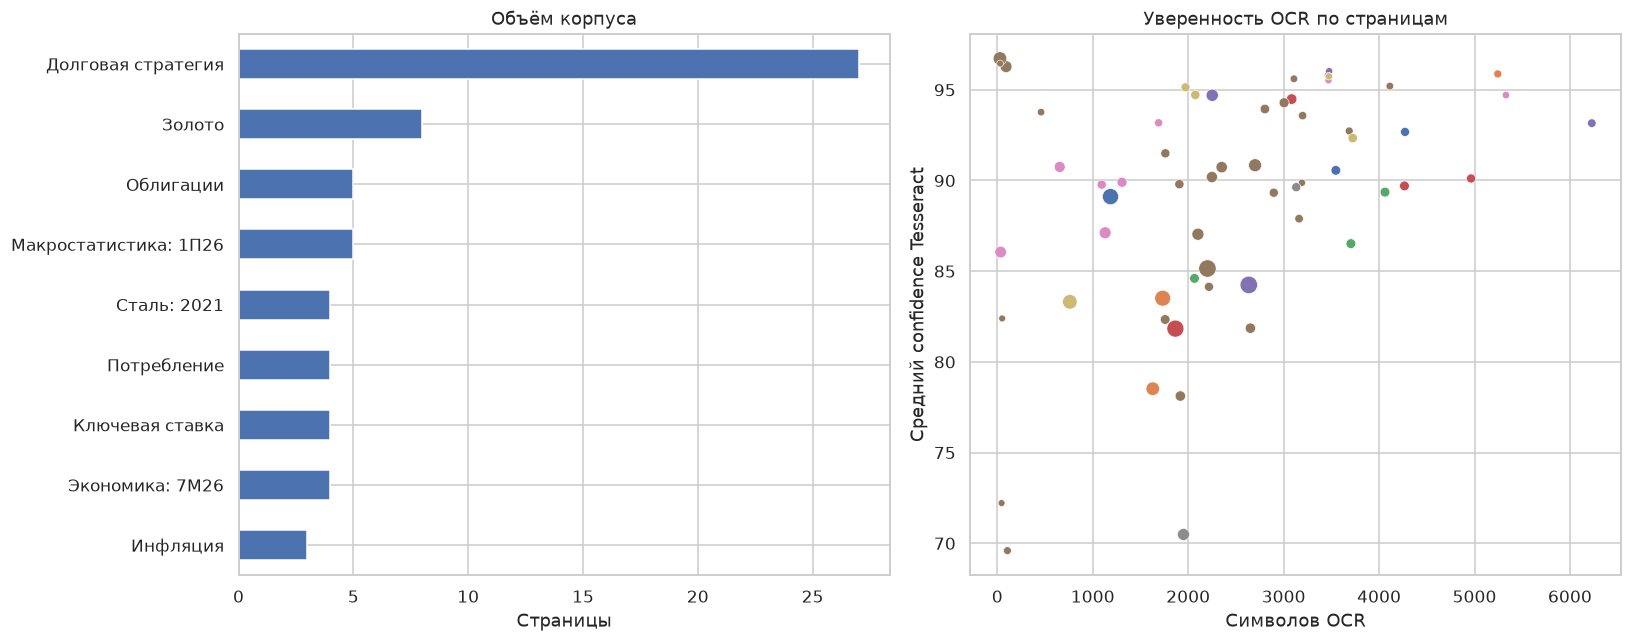

,document,page,native_chars,chars,ocr_words,ocr_confidence,low_confidence_share,digit_share
34,FI_Strategy_3Q26_22072026.pdf,14,0,106,25,69.594,0.320,0.019
57,Inflation_tracker_02.pdf,2,0,1951,367,70.485,0.330,0.127
40,FI_Strategy_3Q26_22072026.pdf,20,0,45,7,72.216,0.286,0.000
35,FI_Strategy_3Q26_22072026.pdf,15,0,1918,346,78.116,0.234,0.078
6,ALFA-Macro_Insights-Policy_Rate_11Sep.pdf,3,0,1629,289,78.519,0.183,0.178
15,ALFA-macro_stat1H26.pdf,4,0,1866,400,81.834,0.168,0.317
38,FI_Strategy_3Q26_22072026.pdf,18,0,2652,461,81.858,0.180,0.077
42,FI_Strategy_3Q26_22072026.pdf,22,0,1759,306,82.335,0.196,0.060
27,FI_Strategy_3Q26_22072026.pdf,7,0,51,6,82.394,0.167,0.000
62,Бонд_Бриф_14092026.pdf,4,0,760,137,83.310,0.161,0.214


In [22]:
short_names = {
    "ALFA-7M26.pdf": "Экономика: 7М26",
    "ALFA-Macro_Insights-Policy_Rate_11Sep.pdf": "Ключевая ставка",
    "ALFA-consumption.pdf": "Потребление",
    "ALFA-macro_stat1H26.pdf": "Макростатистика: 1П26",
    "ALFA_Russian_Steels_1К21PreviewUpdate_15Apr2021.pdf": "Сталь: 2021",
    "FI_Strategy_3Q26_22072026.pdf": "Долговая стратегия",
    "Gold_digest_August26.pdf": "Золото",
    "Inflation_tracker_02.pdf": "Инфляция",
    "Бонд_Бриф_14092026.pdf": "Облигации"
}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pdf_summary.set_index("document").pages.rename(index=short_names).sort_values().plot.barh(
    ax=axes[0]
)
axes[0].set(title="Объём корпуса", xlabel="Страницы", ylabel="")
sns.scatterplot(
    data=pages,
    x="chars",
    y="ocr_confidence",
    hue=pages.document.map(short_names),
    size="digit_share",
    sizes=(20, 130),
    ax=axes[1],
    legend=False,
)
axes[1].set(
    title="Уверенность OCR по страницам", xlabel="Символов OCR", ylabel="Средний confidence Tesseract"
)
plt.tight_layout()
plt.show()
display(
    pages.sort_values("ocr_confidence")
    .head(12)[
        [
            "document",
            "page",
            "native_chars",
            "chars",
            "ocr_words",
            "ocr_confidence",
            "low_confidence_share",
            "digit_share",
        ]
    ]
    .round(3)
)

Все 64 страницы требуют OCR. Малое число символов на титульной странице само по себе не означает потерю текста. Для таблиц, мелких подписей и графиков необходима проверка макета: текстовое распознавание не восстанавливает связи между значениями, подписями и единицами измерения.

Результаты выборочной визуальной проверки:

- На с. 1 `ALFA-macro_stat1H26.pdf` напечатано «1П26», в OCR получилось «11126». Даже заголовок требует проверки периода.
- С. 14 долговой стратегии — разделитель на красном фоне. Низкий confidence здесь не равен потере аналитической таблицы.
- С. 3 отчёта о потреблении содержит два графика: текстовое OCR не сохраняет связь точек, осей и подписей.
- Четыре отчёта имеют одинаковую завершающую страницу с контактами и дисклеймером. Это повтор служебной страницы, а не четыре копии одного события. Его не стоит использовать как основание персонального вывода.

Номера здесь — позиции страниц PDF с единицы; напечатанный на листе номер может отличаться.

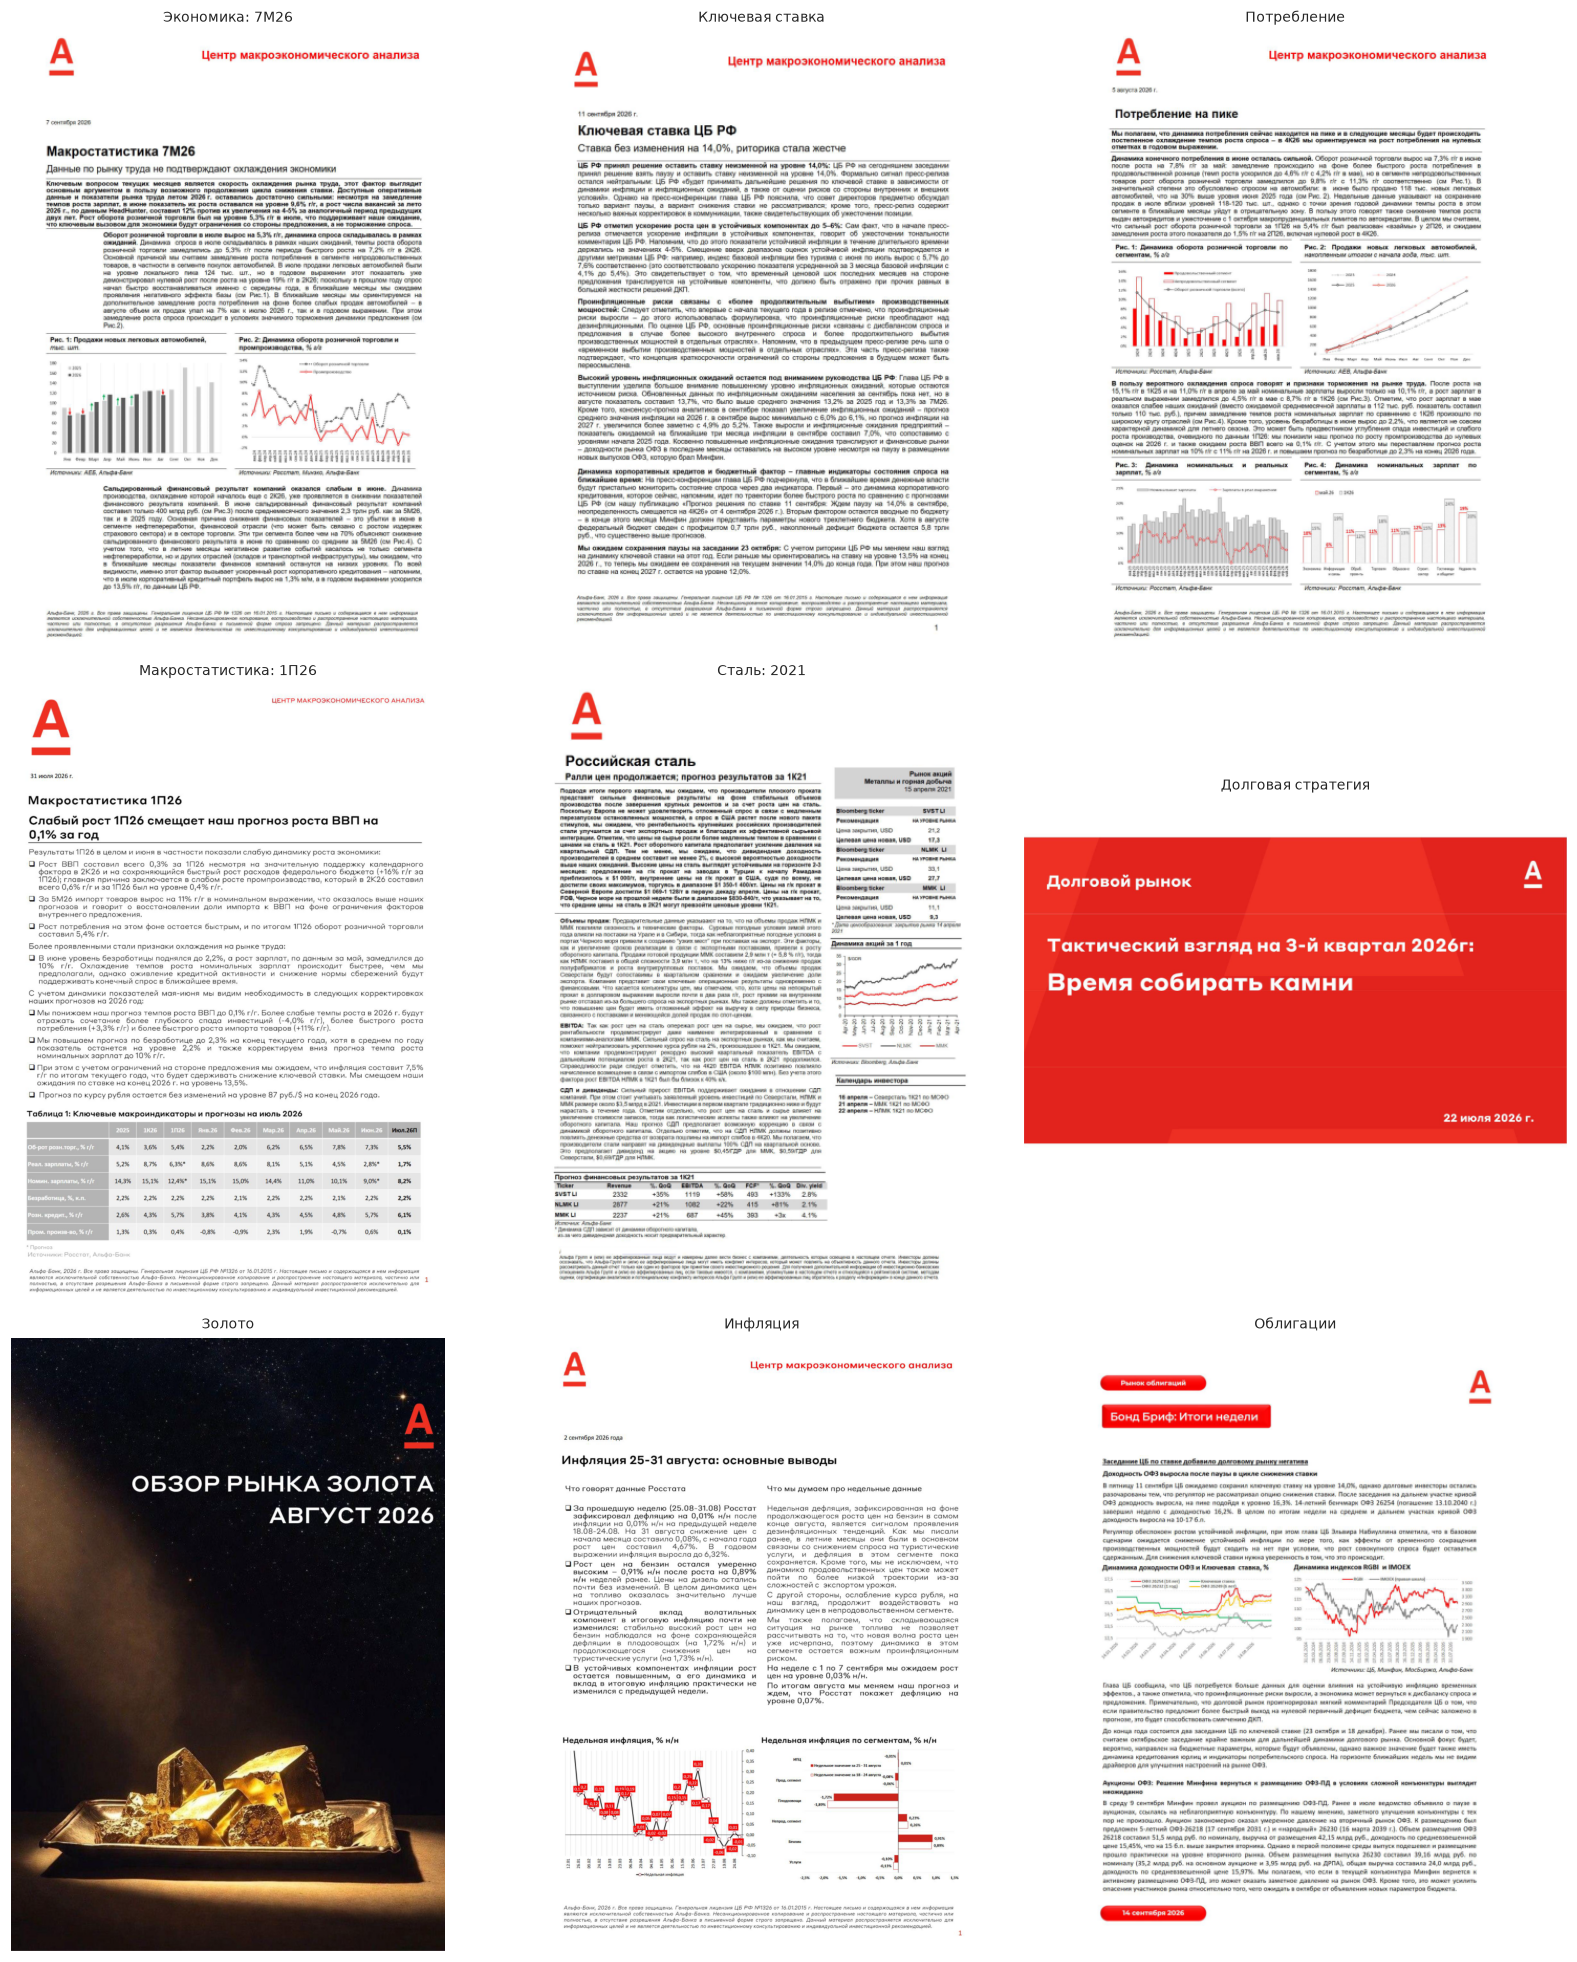

In [23]:
import pymupdf
from PIL import Image

fig, axes = plt.subplots(3, 3, figsize=(15, 18))
for ax, name in zip(axes.flat, documents.document):
    with pymupdf.open(DATA / "reports" / name) as doc:
        pix = doc[0].get_pixmap(dpi=50, alpha=False)
        ax.imshow(Image.frombytes("RGB", (pix.width, pix.height), pix.samples))
    ax.set_title(short_names[name], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 16. Даты публикации и временная утечка

Даты определены по первым страницам документов; для обзора золота известен только месяц, без подстановки условного дня. Метаданные PDF описывают техническое создание файла и могут отличаться от даты публикации.

,document,publication,precision,basis,pdf_created,age_days
0,ALFA-7M26.pdf,2026-09-07,day,первая страница,D:20260928114514Z00'00',44
1,ALFA-Macro_Insights-Policy_Rate_11Sep.pdf,2026-09-11,day,первая страница,D:20260928113932Z00'00',40
2,ALFA-consumption.pdf,2026-08-05,day,первая страница,D:20260928113827Z00'00',77
3,ALFA-macro_stat1H26.pdf,2026-07-31,day,первая страница,D:20260928114643Z00'00',82
4,ALFA_Russian_Steels_1К21PreviewUpdate_15Apr2021.pdf,2021-04-15,day,первая страница и имя файла,D:20260928113550Z00'00',2015
5,FI_Strategy_3Q26_22072026.pdf,2026-07-22,day,первая страница,D:20260928115134Z00'00',91
6,Gold_digest_August26.pdf,2026-08,month,месяц на обложке,D:20260928115346Z00'00',<NA>
7,Inflation_tracker_02.pdf,2026-09-02,day,первая страница,D:20260928115447Z00'00',49
8,Бонд_Бриф_14092026.pdf,2026-09-14,day,первая страница и имя файла,D:20260928115614Z00'00',37


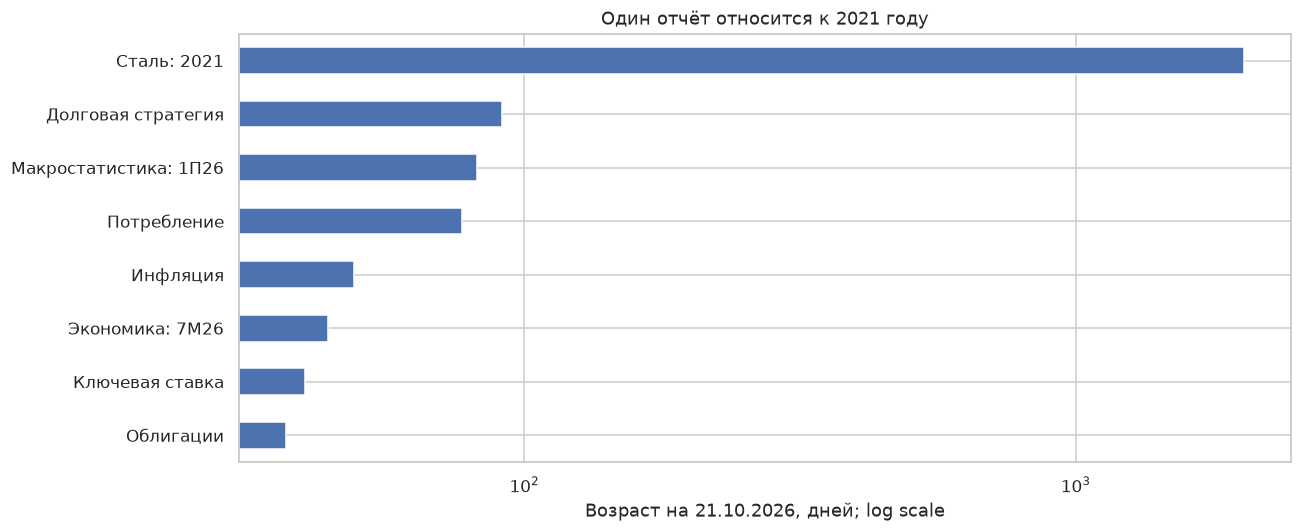

In [24]:
publication = pd.DataFrame(
    [
        ["ALFA-7M26.pdf", "2026-09-07", "day", "первая страница"],
        ["ALFA-Macro_Insights-Policy_Rate_11Sep.pdf", "2026-09-11", "day", "первая страница"],
        ["ALFA-consumption.pdf", "2026-08-05", "day", "первая страница"],
        ["ALFA-macro_stat1H26.pdf", "2026-07-31", "day", "первая страница"],
        [
            "ALFA_Russian_Steels_1К21PreviewUpdate_15Apr2021.pdf",
            "2021-04-15",
            "day",
            "первая страница и имя файла",
        ],
        ["FI_Strategy_3Q26_22072026.pdf", "2026-07-22", "day", "первая страница"],
        ["Gold_digest_August26.pdf", "2026-08", "month", "месяц на обложке"],
        ["Inflation_tracker_02.pdf", "2026-09-02", "day", "первая страница"],
        ["Бонд_Бриф_14092026.pdf", "2026-09-14", "day", "первая страница и имя файла"],
    ],
    columns=["document", "publication", "precision", "basis"],
)
publication["pdf_created"] = publication.document.map(
    documents.set_index("document").metadata.map(lambda d: d.get("creationDate"))
)
publication["age_days"] = pd.NA
known = publication.precision.eq("day")
publication.loc[known, "age_days"] = (
    publication.loc[known, "publication"].map(
        lambda value: (date(2026, 10, 21) - date.fromisoformat(value)).days
    )
)
assert publication.loc[publication.document.str.contains("Steels"), "age_days"].iloc[0] == 2015
assert publication.loc[~known, "age_days"].isna().all()
display(publication)
fig, ax = plt.subplots(figsize=(12, 5))
publication.loc[known].assign(label=lambda d: d.document.map(short_names)).set_index(
    "label"
).age_days.astype(int).sort_values().plot.barh(ax=ax)
ax.set(
    xscale="log",
    xlabel="Возраст на 21.10.2026, дней; log scale",
    ylabel="",
    title="Один отчёт относится к 2021 году",
)
plt.tight_layout()
plt.show()

Отчёт по стали опубликован в 2021 году, остальные выпуски — в 2026. Дата создания PDF в сентябре 2026 года не делает старый прогноз актуальным.

В CSV нет дат платежей, профилей и связей. Поэтому сезонность, динамику и качество на будущих событиях по этой выгрузке не оценить.

## 17. Повторяющийся текст и темы документов


,line,documents
31,"распространение настоящего материала, частично или",9
27,"несанкционированное копирование, воспроизводство и",7
14,настоящий отчет и содержащаяся в нем информация являются исключительной собственностью альфа-банка.,6
43,являются исключительной собственностью альфа-банка.,5
38,"несанкционированное копирование, воспроизводство и распространение настоящего материала, частичн...",5
21,"полностью, в отсутствие разрешения альфа-банка в письменной форме строго запрещено.",5
42,"полностью, в отсутствие разрешения альфа-банка в",5
37,"федерации. он не предназначен для распространения среди частных инвесторов. несмотря на то, что",4
36,"зависимости от курса иностранных валют, принимают на себя валютный риск. инвестиции в россии и в",4
35,"валютного курса, которые могут привести к снижению их стоимости, цены или дохода от вложений в н...",4


Символы в точных междокументных повторах, %: 10.39


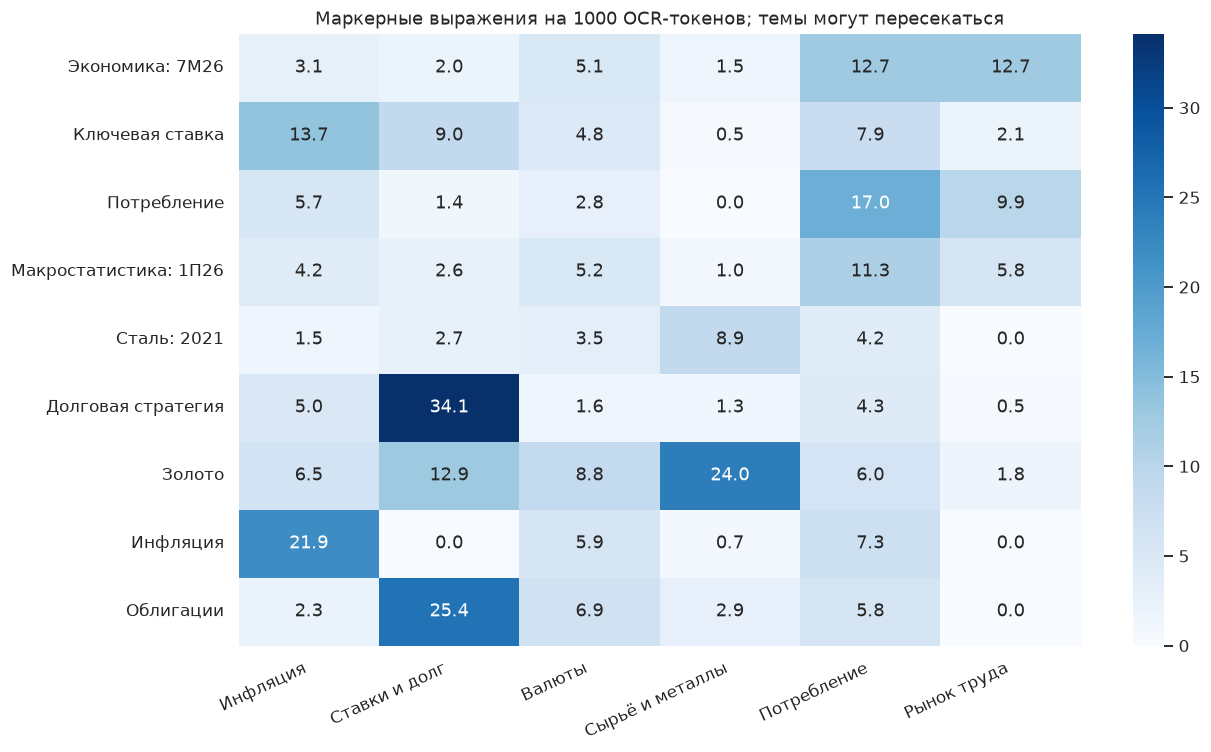

In [25]:
def normalize_line(s):
    return re.sub(r"\s+", " ", s.casefold().replace("ё", "е")).strip()


line_documents = {}
for row in pages.itertuples():
    for line in set(normalize_line(s) for s in row.text.splitlines() if len(s.strip()) >= 40):
        line_documents.setdefault(line, set()).add(row.document)
repeated = {line: docs for line, docs in line_documents.items() if len(docs) >= 3}
display(
    pd.DataFrame(
        [{"line": line, "documents": len(docs)} for line, docs in repeated.items()],
        columns=["line", "documents"],
    )
    .sort_values("documents", ascending=False)
    .head(20)
)
pages["repeated_chars"] = pages.text.map(
    lambda s: sum(len(line) for line in s.splitlines() if normalize_line(line) in repeated)
)
print(
    "Символы в точных междокументных повторах, %:",
    round(pages.repeated_chars.sum() / pages.chars.sum() * 100, 2),
)
topic_patterns = {
    "Инфляция": r"инфляц|дефляц|рост цен",
    "Ставки и долг": r"ставк|облигац|доходност|офз",
    "Валюты": r"валют|доллар|курс|рубл",
    "Сырьё и металлы": r"золот|стал[ьи]|металл|нефт|сырь",
    "Потребление": r"потреблен|рознич|спрос",
    "Рынок труда": r"зарплат|ваканс|безработ|рын[а-я]* труда",
}
doc_text = pages.groupby("document", sort=False).text.agg("\n".join)
topics = pd.DataFrame(
    {topic: doc_text.str.lower().str.count(pattern) for topic, pattern in topic_patterns.items()}
)
topics = topics.div(doc_text.str.findall(r"\w+").str.len(), axis=0) * 1000
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(topics.rename(index=short_names), annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set(
    title="Маркерные выражения на 1000 OCR-токенов; темы могут пересекаться", xlabel="", ylabel=""
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

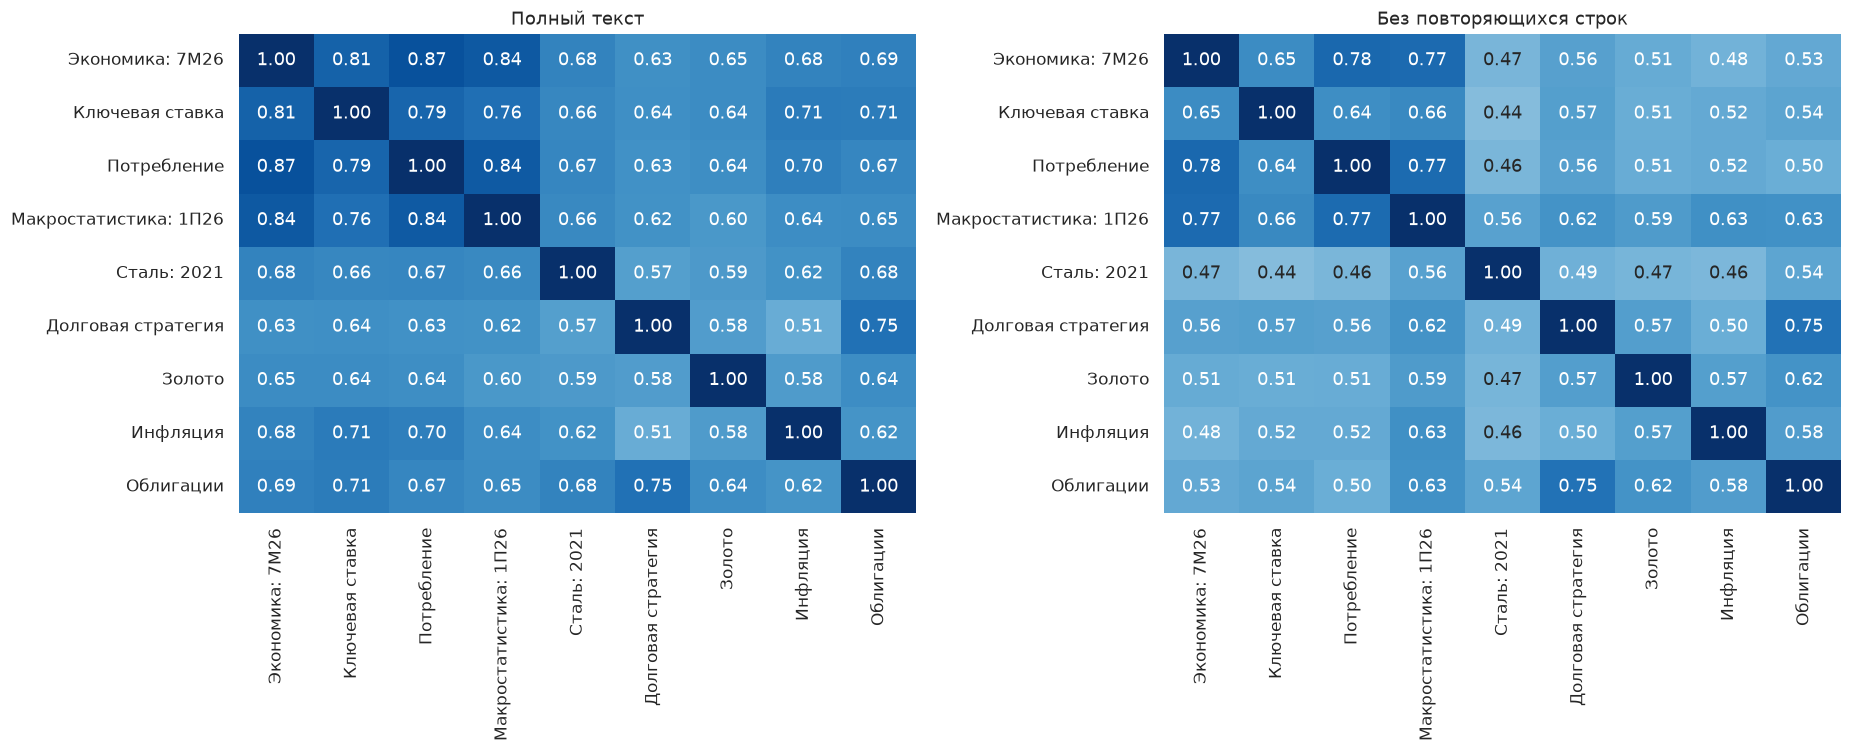

,document_1,document_2,before,after,drop
10,Ключевая ставка,Сталь: 2021,0.664,0.437,0.227
3,Экономика: 7М26,Сталь: 2021,0.682,0.466,0.216
16,Потребление,Сталь: 2021,0.670,0.464,0.206
6,Экономика: 7М26,Инфляция,0.683,0.484,0.199
13,Ключевая ставка,Инфляция,0.714,0.523,0.191
19,Потребление,Инфляция,0.699,0.520,0.179
7,Экономика: 7М26,Облигации,0.694,0.525,0.169
28,Сталь: 2021,Инфляция,0.625,0.459,0.166
20,Потребление,Облигации,0.669,0.503,0.166
14,Ключевая ставка,Облигации,0.710,0.545,0.165


,document,removed_chars_pct
0,Экономика: 7М26,31.69
1,Ключевая ставка,32.74
2,Потребление,29.72
3,Макростатистика: 1П26,1.42
4,Сталь: 2021,23.37
5,Долговая стратегия,0.47
6,Золото,1.71
7,Инфляция,1.78
8,Облигации,4.47


In [26]:
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=20000)
doc_matrix = vectorizer.fit_transform(doc_text)
similarity = pd.DataFrame(
    cosine_similarity(doc_matrix), index=doc_text.index, columns=doc_text.index
)
pages["without_repeats"] = pages.text.map(
    lambda text: "\n".join(
        line for line in text.splitlines() if normalize_line(line) not in repeated
    )
)
clean_doc_text = pages.groupby("document", sort=False).without_repeats.agg("\n".join)
# Словарь и IDF фиксированы, чтобы сравнить только эффект удаления строк.
clean_similarity = pd.DataFrame(
    cosine_similarity(vectorizer.transform(clean_doc_text)),
    index=doc_text.index, columns=doc_text.index,
)
assert clean_doc_text.index.equals(doc_text.index)
assert clean_doc_text.str.len().le(doc_text.str.len()).all()

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for matrix, title, ax in zip(
    [similarity, clean_similarity], ["Полный текст", "Без повторяющихся строк"], axes
):
    sns.heatmap(
        matrix.rename(index=short_names, columns=short_names), annot=True,
        fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
    )
    ax.set(title=title, xlabel="", ylabel="")
plt.tight_layout()
plt.show()

left, right = np.triu_indices(len(doc_text), k=1)
similarity_changes = pd.DataFrame({
    "document_1": doc_text.index[left].map(short_names),
    "document_2": doc_text.index[right].map(short_names),
    "before": similarity.to_numpy()[left, right],
    "after": clean_similarity.to_numpy()[left, right],
})
similarity_changes["drop"] = similarity_changes.before - similarity_changes.after
display(similarity_changes.sort_values("drop", ascending=False).head(10).round(3))
display(pd.DataFrame({
    "document": doc_text.index.map(short_names),
    "removed_chars_pct": (1 - clean_doc_text.str.len() / doc_text.str.len()).to_numpy() * 100,
}).round(2))


Повторы составляют **10,39% символов OCR**. После их удаления средняя косинусная близость разных документов падает с **0,673 до 0,570**. Самое заметное изменение — у обзора ставки и отчёта по стали 2021 года: **0,664 → 0,437**. Общий шаблон заметно сближает разные по теме и времени документы.

Для сравнения удалены точные строки длиной от 40 символов, встречающиеся хотя бы в трёх документах. Словарь и веса TF-IDF оставлены прежними. Так видно, какую часть похожести создаёт повторяющийся текст. Это диагностический опыт: повторяться могут и содержательные фразы, поэтому автоматически удалять всё найденное из рабочего поиска пока рано.

Темы определены регулярными выражениями и могут пересекаться. Девять выбранных отчётов не представляют будущий поток новостей; доли тем нельзя переносить на него.

## 18. Размеры текстовых фрагментов


,size,overlap,chunks,stored_chars,duplication_factor,shorter_than_200
0,800,100,251,177882,1.117,12
1,1500,200,151,176582,1.109,7
2,2500,300,100,169982,1.068,7


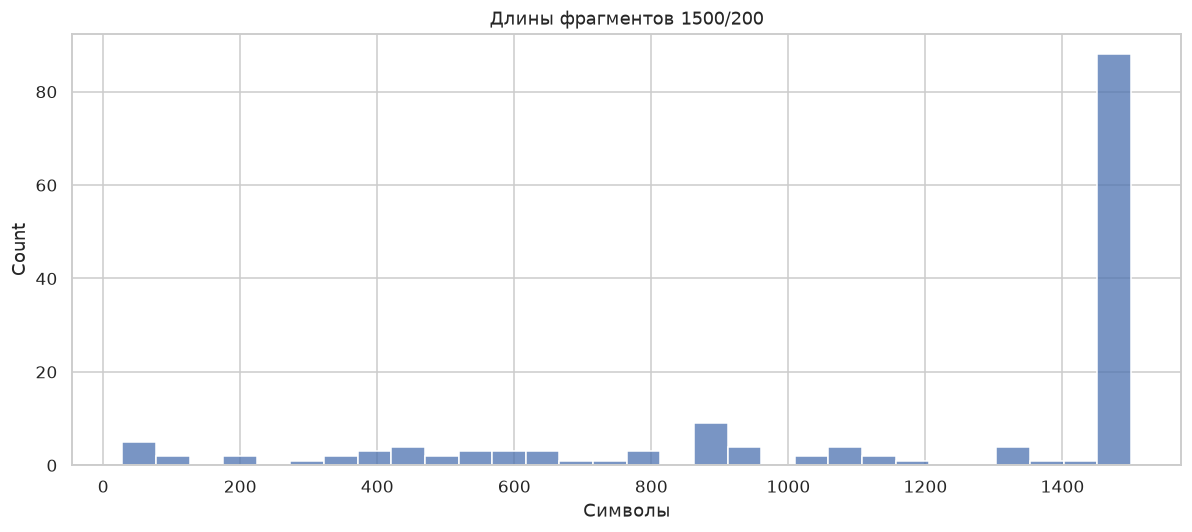

In [27]:
def make_chunks(page_frame, size=1500, overlap=200):
    assert size > overlap >= 0
    rows = []
    for page in page_frame.itertuples():
        text = page.text
        for start in range(0, len(text), size - overlap):
            end = min(start + size, len(text))
            rows.append(
                {
                    "document": page.document,
                    "page": page.page,
                    "start": start,
                    "end": end,
                    "chunk_id": f"{page.document}:p{page.page}:{start}-{end}",
                    "text": text[start:end],
                }
            )
            if end == len(text):
                break
    return pd.DataFrame(rows)


chunks = make_chunks(pages)
assert all(r.end - r.start == len(r.text) for r in chunks.itertuples())
assert not chunks.chunk_id.duplicated().any()
chunk_comparison = []
for size, overlap in [(800, 100), (1500, 200), (2500, 300)]:
    variant = make_chunks(pages, size, overlap)
    chunk_comparison.append(
        {
            "size": size,
            "overlap": overlap,
            "chunks": len(variant),
            "stored_chars": variant.text.str.len().sum(),
            "duplication_factor": variant.text.str.len().sum() / pages.chars.sum(),
            "shorter_than_200": variant.text.str.len().lt(200).sum(),
        }
    )
display(pd.DataFrame(chunk_comparison).round(3))
fig, ax = plt.subplots()
sns.histplot(chunks.text.str.len(), bins=30, ax=ax)
ax.set(title="Длины фрагментов 1500/200", xlabel="Символы")
plt.tight_layout()
plt.show()

Сравниваются три размера фрагмента с перекрытием. Разбиение сохраняет страницу и позиции символов, но не восстанавливает колонки, таблицы и подписи графиков. Перекрытие увеличивает объём текста и не исправляет OCR.

## 19. Локальный поиск: диагностические примеры

BM25 работает по исходному OCR, включая повторяющийся текст. Запросы составлены по темам корпуса и показывают поведение поиска. Это не независимый тест качества: для recall@k нужна экспертная разметка релевантных фрагментов.


In [28]:
from rank_bm25 import BM25Plus
from snowballstemmer import stemmer

russian_stemmer = stemmer("russian")
STOP_WORDS = set("и в во на по из за для с со от до а но или как что это при о об к не".split())


def tokens(text):
    words = re.findall(r"[\w]+", text.lower().replace("ё", "е"))
    return russian_stemmer.stemWords(
        [word for word in words if len(word) > 2 and word not in STOP_WORDS]
    )


corpus = [tokens(text) or ["_empty_"] for text in chunks.text]
index = BM25Plus(corpus)
queries = [
    "Почему Центральный банк сохранил ключевую ставку в сентябре?",
    "Как меняются инфляция и цены на бензин?",
    "Что происходит с потреблением и рынком труда?",
    "Каковы ожидания по ценам на сталь и дивидендам металлургов?",
    "Как оцениваются золото и спрос на него?",
    "Какие условия действуют в договоре хеджирования компании U_67?",
]
search_results = []
for query in queries:
    query_tokens = tokens(query)
    scores = index.get_scores(query_tokens)
    # BM25Plus может дать ненулевой балл без общих слов; такие фрагменты исключаются.
    eligible = [i for i, words in enumerate(corpus) if set(query_tokens) & set(words)]
    best = sorted(eligible, key=lambda i: -scores[i])[:3]
    if not best:
        search_results.append(
            {
                "query": query,
                "rank": None,
                "document": None,
                "page": None,
                "score": None,
                "excerpt": "Нет лексических совпадений",
            }
        )
    for rank, i in enumerate(best, 1):
        r = chunks.iloc[i]
        search_results.append(
            {
                "query": query,
                "rank": rank,
                "document": r.document,
                "page": r.page,
                "score": float(scores[i]),
                "excerpt": r.text[:320],
            }
        )
display(pd.DataFrame(search_results).round(3))


,query,rank,document,page,score,excerpt
0,Почему Центральный банк сохранил ключевую ставку в сентябре?,1,Gold_digest_August26.pdf,2,27.238,"Между\nтем, безработица сохранилась на уровне 41%. Сильная\nстатистика заставила трейдеров актив..."
1,Почему Центральный банк сохранил ключевую ставку в сентябре?,2,Бонд_Бриф_14092026.pdf,1,27.177,Бонд Бриф: Итоги недели\nЗаседание ЦБ по ставке добавило долговому рынку негатива\nДоходность ОФ...
2,Почему Центральный банк сохранил ключевую ставку в сентябре?,3,Gold_digest_August26.pdf,5,27.025,Ставка ФРС не менялась;\nизменились ожидания ее следующего шага\nЦелевой диапазон ставки на коне...
3,Как меняются инфляция и цены на бензин?,1,Inflation_tracker_02.pdf,1,20.435,"м про недельные данные\nНедельная дефляция, зафиксированная на фоне\nпродолжающегося роста цен н..."
4,Как меняются инфляция и цены на бензин?,2,Inflation_tracker_02.pdf,1,20.271,Центр макроэкономического анализа\n2 сентября 2026 года\nИнфляция 25-31 августа: основные выводы...
5,Как меняются инфляция и цены на бензин?,3,ALFA-consumption.pdf,2,16.990,"S\nhy | 170\n60 oan a ыы 150\n50 У. 130\n40 \ | 2,5% 110\non <\nы luli ы\n20 J TTT 2.0% 70\nSRAS..."
6,Что происходит с потреблением и рынком труда?,1,ALFA-consumption.pdf,1,17.560,"Центр макроэкономического анализа\ni\n5 августа 2026 г.\nПотребление на пике\nМы полагаем, что д..."
7,Что происходит с потреблением и рынком труда?,2,ALFA-macro_stat1H26.pdf,1,16.535,ЦЕНТР МАКРОЭКОНОМИЧЕСКОГО АНАЛИЗА\n31 июля 2026 г.\nМакростатистика 11126\nСлабый рост 11126 сме...
8,Что происходит с потреблением и рынком труда?,3,ALFA-7M26.pdf,1,15.892,Центр макроэкономического анализа\n7 сентября 2026\nМакростатистика 7М26\nДанные по рынку труда ...
9,Каковы ожидания по ценам на сталь и дивидендам металлургов?,1,ALFA_Russian_Steels_1К21PreviewUpdate_15Apr2021.pdf,1,19.529,"вышение цен будет иметь отложенный эффект на выручку в силу природы бизнеса,\nсвязанного с поста..."


Последний вопрос намеренно требует отсутствующий договор. Лексические совпадения слов «компания» или «условия» всё равно могут поднять фрагменты. Поисковый балл не подтверждает достаточность основания: это требует отдельной проверки на этапе оценки. Анонимный `U_67` нельзя автоматически связать с названием реального эмитента из PDF.

## 20. Справочник Excel: полнота и ссылочная целостность

In [29]:
profile = pd.read_excel(WORKBOOK, sheet_name="1. Профиль компании", header=3, dtype=str)
role_links = pd.read_excel(WORKBOOK, sheet_name="2. Роли директоров", header=3, dtype=str)
sources = pd.read_excel(WORKBOOK, sheet_name="3. Источники", header=3, dtype=str)
profile = profile[profile.ID.str.fullmatch(r"[ИБГСО]\d+", na=False)].copy()
role_links[["Роль", "Главный вопрос / KPI", "Что важно"]] = role_links[
    ["Роль", "Главный вопрос / KPI", "Что важно"]
].ffill()
role_links = role_links[role_links["Профиль компании: ID (ссылка)"].notna()].copy()
sources = sources[sources.ID.str.fullmatch(r"S\d+", na=False)].copy()
source_edges = []
for row in sources.to_dict("records"):
    for element in re.findall(
        r"(?m)^([ИБГСО]\d+)\b", row["Профиль компании (элементы, которые питает источник)"] or ""
    ):
        source_edges.append({"source": row["ID"], "element": element})
source_edges = pd.DataFrame(source_edges)
profile_ids = set(profile.ID)
source_ids = set(sources.ID)
referenced_sources = set(re.findall(r"S\d{3}", " ".join(profile.iloc[:, -1].fillna(""))))
audit = pd.Series(
    {
        "profile_elements": len(profile),
        "roles": role_links["Роль"].nunique(),
        "role_element_links": len(role_links),
        "sources": len(sources),
        "source_element_links": len(source_edges),
        "duplicate_profile_ids": profile.ID.duplicated().sum(),
        "duplicate_source_ids": sources.ID.duplicated().sum(),
        "unknown_role_elements": (
            ~role_links["Профиль компании: ID (ссылка)"].isin(profile_ids)
        ).sum(),
        "unknown_source_elements": (~source_edges.element.isin(profile_ids)).sum(),
        "unknown_source_ids_in_profile": len(referenced_sources - source_ids),
        "missing_role_names": role_links["Роль"].isna().sum(),
    }
)
display(audit.to_frame("value"))
display(profile.iloc[:, :3])


,value
profile_elements,33
roles,9
role_element_links,71
sources,149
source_element_links,255
duplicate_profile_ids,0
duplicate_source_ids,0
unknown_role_elements,0
unknown_source_elements,0
unknown_source_ids_in_profile,0


,ID,Блок,Элемент профиля
0,И1,Идентификация,Регистрационные данные
1,И2,Идентификация,Собственники и группа компаний
2,И3,Идентификация,Ценные бумаги и кредитные рейтинги
3,И4,Идентификация,"Бренды, товарные знаки, домены"
4,И5,Идентификация,Особые статусы
5,И6,Идентификация,Санкционный статус
6,И7,Идентификация,Правовой статус и надёжность
7,Б1,Бизнес,Отрасль и виды деятельности
8,Б2,Бизнес,Финансовые результаты
9,Б3,Бизнес,Долг и чувствительность к ставке


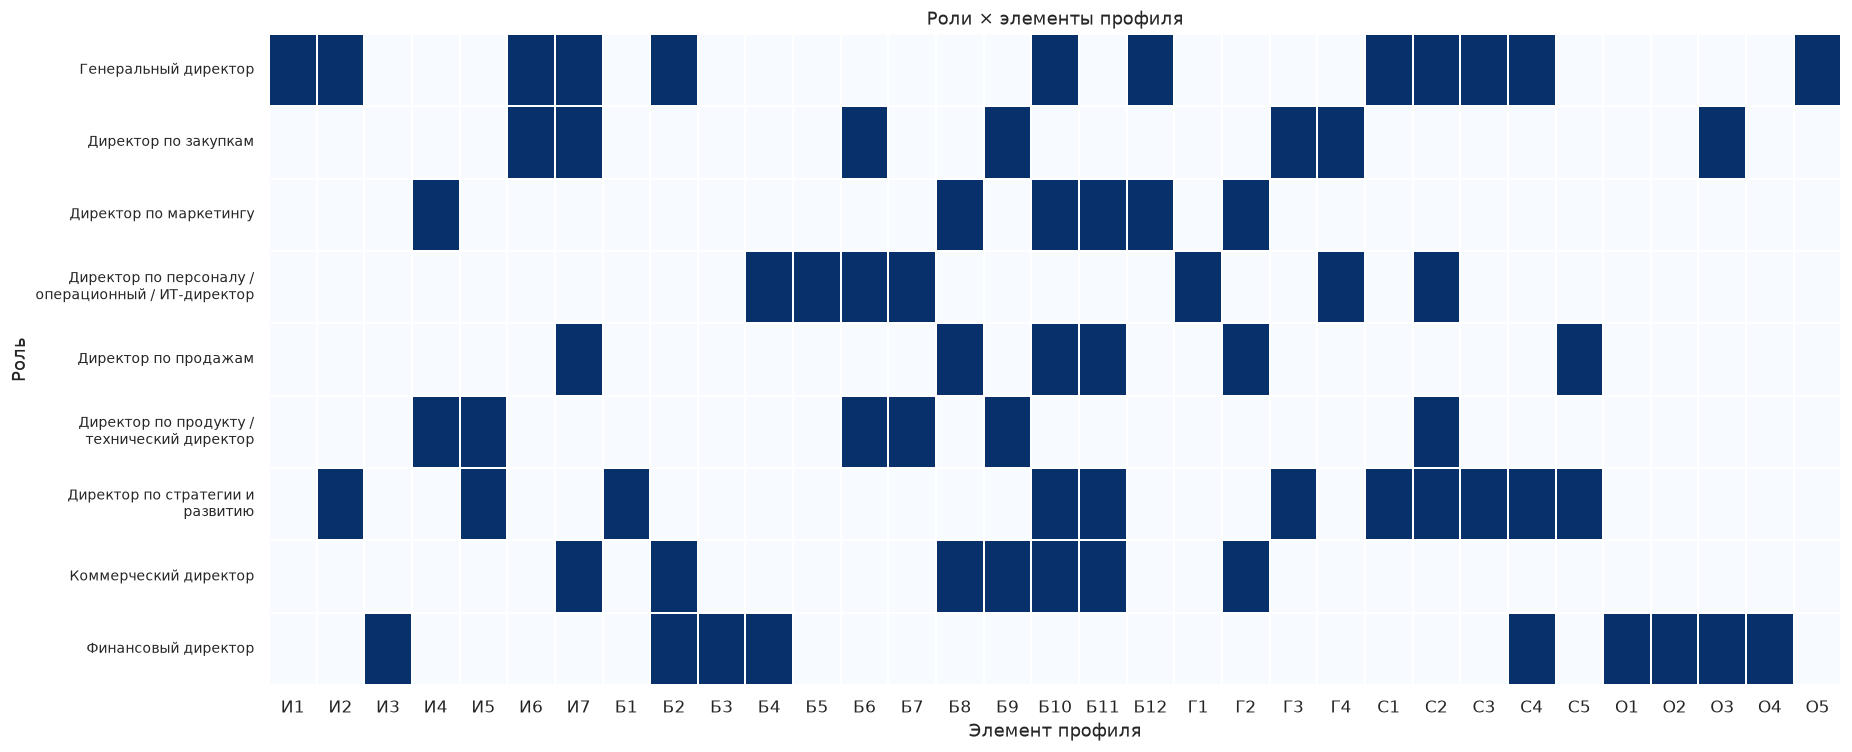

,ID,Блок,Элемент профиля,source_count,role_count
28,О1,Отношения с банком,Расчёты и денежный поток,2,1
3,И4,Идентификация,"Бренды, товарные знаки, домены",2,2
31,О4,Отношения с банком,Размещение средств,3,1
32,О5,Отношения с банком,Канал и пользователи,3,1
29,О2,Отношения с банком,Кредиты и ковенанты,4,1
10,Б4,Бизнес,Налоги и обязательные платежи,4,2
13,Б7,Бизнес,Технологии и ИТ,4,2
30,О3,Отношения с банком,Валютные операции и хеджирование,4,2
1,И2,Идентификация,Собственники и группа компаний,5,2
4,И5,Идентификация,Особые статусы,5,2


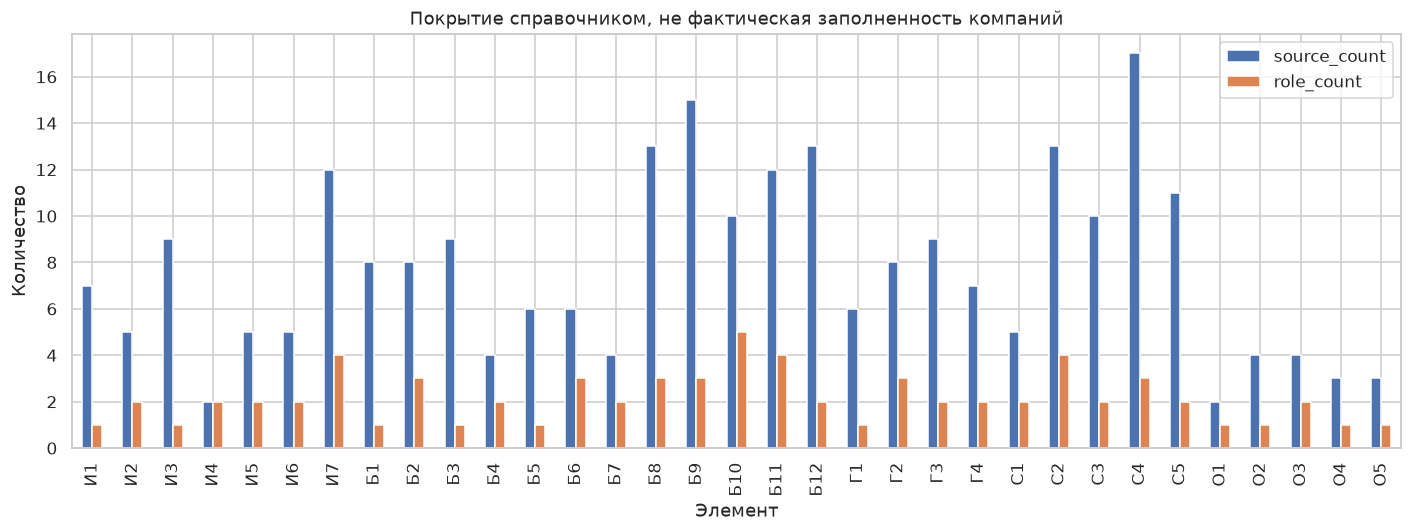

In [30]:
role_matrix = pd.crosstab(
    role_links["Роль"], role_links["Профиль компании: ID (ссылка)"]
).reindex(columns=profile.ID, fill_value=0)
fig, ax = plt.subplots(figsize=(17, 7))
sns.heatmap(role_matrix, cmap="Blues", cbar=False, linewidths=0.3, ax=ax)
ax.set_yticklabels([fill(role, 28) for role in role_matrix.index], rotation=0, fontsize=9)
ax.set(title="Роли × элементы профиля", xlabel="Элемент профиля", ylabel="Роль")
plt.tight_layout()
plt.show()
coverage_elements = profile[["ID", "Блок", "Элемент профиля"]].copy()
coverage_elements["source_count"] = (
    coverage_elements.ID.map(source_edges.groupby("element").source.nunique()).fillna(0).astype(int)
)
coverage_elements["role_count"] = (
    coverage_elements.ID.map(
        role_links.groupby("Профиль компании: ID (ссылка)")["Роль"].nunique()
    )
    .fillna(0)
    .astype(int)
)
display(coverage_elements.sort_values(["source_count", "role_count"]))
fig, ax = plt.subplots(figsize=(13, 5))
coverage_elements.set_index("ID")[["source_count", "role_count"]].plot.bar(ax=ax)
ax.set(
    title="Покрытие справочником, не фактическая заполненность компаний",
    ylabel="Количество",
    xlabel="Элемент",
)
plt.tight_layout()
plt.show()


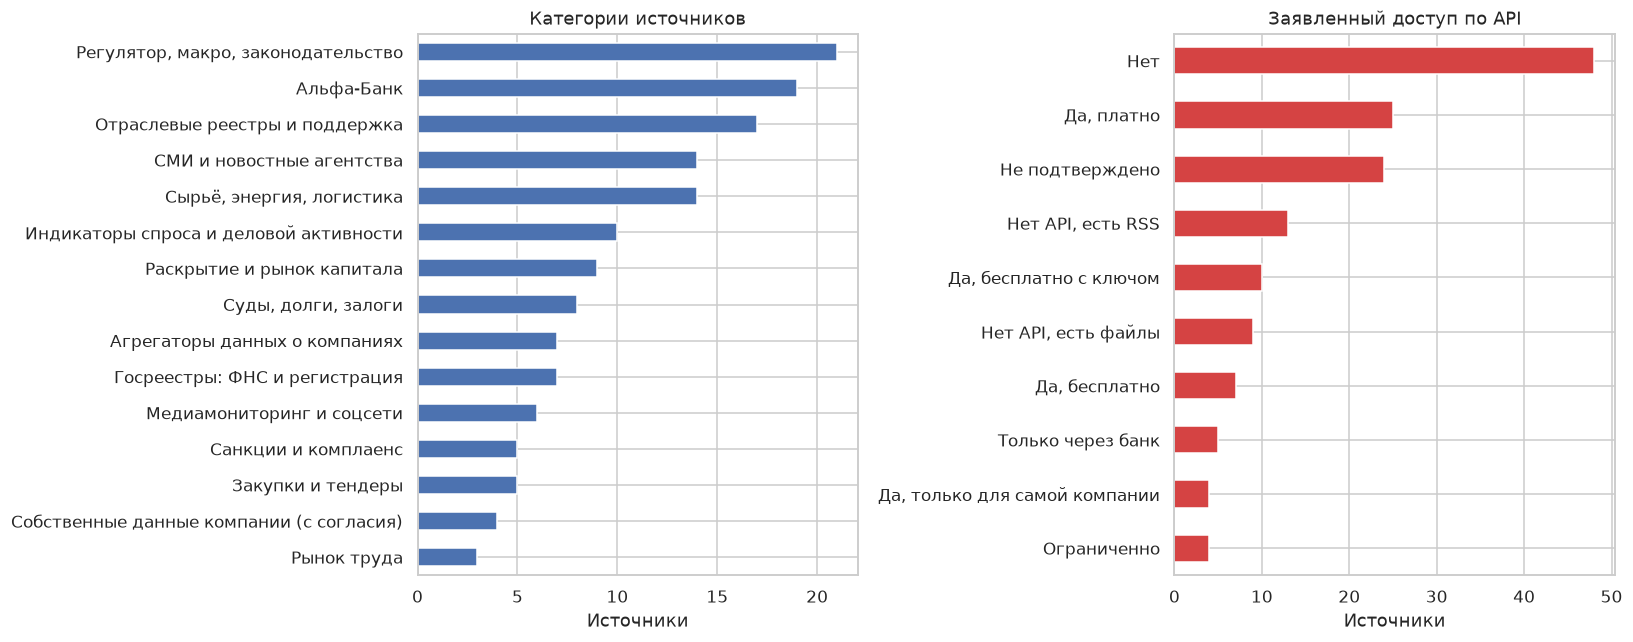

,count
urls_without_http_scheme,149
distinct_hosts,135
distinct_urls,142


In [31]:
def api_category(text):
    prefixes = [
        "Да, бесплатно с ключом",
        "Да, бесплатно",
        "Да, платно",
        "Да, только для самой компании",
        "Только через банк",
        "Нет API, есть файлы",
        "Нет API, есть RSS",
        "Ограниченно",
        "Не подтверждено",
        "Нет",
    ]
    return next((p for p in prefixes if str(text).startswith(p)), str(text).split(".")[0][:60])


sources["api_category"] = sources["Доступ по API"].map(api_category)
sources["url_has_scheme"] = sources["Ссылка"].fillna("").str.match(r"^https?://")
sources["host"] = (
    sources["Ссылка"]
    .fillna("")
    .map(lambda s: urlsplit(s if "://" in s else "https://" + s).hostname)
)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sources["Категория"].value_counts().sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Категории источников", xlabel="Источники", ylabel="")
sources.api_category.value_counts().sort_values().plot.barh(ax=axes[1], color="#D54343")
axes[1].set(title="Заявленный доступ по API", xlabel="Источники", ylabel="")
plt.tight_layout()
plt.show()
display(
    pd.Series(
        {
            "urls_without_http_scheme": int((~sources.url_has_scheme).sum()),
            "distinct_hosts": sources.host.nunique(),
            "distinct_urls": sources["Ссылка"].nunique(),
        }
    ).to_frame("count")
)


Пустые роли в Excel — следствие объединённых ячеек. Значения перенесены вниз только в колонках роли, вопроса и фокуса.

Статусы API взяты из справочника. Доступность сайтов и условия подключения не проверялись; 149 строк не означают 149 работающих каналов.

## 21. Какие элементы профиля покрыты данными


In [32]:
context_map = pd.DataFrame(
    [
        [
            "И1",
            "частично",
            "анонимный ID, тип собственности, география",
            "нет ИНН/ОГРН/названия; нельзя связывать с реальными компаниями",
        ],
        ["И2", "частично", "GROUP_ID, связи F–U", "нет долей и типов владения; неполное покрытие"],
        [
            "Б1",
            "частично",
            "ОКВЭД и название деятельности",
            "нет продуктового состава и долей сегментов",
        ],
        ["Б2", "частично", "REVENUE_COMPANY", "нет прибыли, денежных потоков, явного года"],
        [
            "Б3",
            "очень ограниченно",
            "флаг кредитного продукта",
            "нет суммы долга, ставки, срока, валюты",
        ],
        [
            "Б5",
            "частично",
            "категории штата ФНС/SPARK",
            "SPARK почти пустой, точной численности нет",
        ],
        ["Б8", "кандидатные связи", "входящие платежи", "получение денег не доказывает продажу"],
        ["Б9", "кандидатные связи", "исходящие платежи", "нет сырья, договоров и назначения"],
        ["Г1", "частично", "CITY, REGION профиля", "нет координат площадок и состава активов"],
        ["Г3", "частично", "FTS_FLAG, список стран", "нет импорт/экспорт, валют и долей"],
        ["О1", "частично", "агрегаты PAY_AMT/PAY_CNT", "нет дат, остатков и назначения"],
        ["О2", "очень ограниченно", "кредитные/гарантийные флаги", "нет договоров и ковенантов"],
        ["О4", "очень ограниченно", "флаг депозитного продукта", "нет сумм и сроков размещения"],
        [
            "О5",
            "нет",
            "роли перечислены только в справочнике",
            "нет назначения ролей конкретным людям",
        ],
    ],
    columns=["element", "coverage", "available", "missing"],
)
display(context_map)
print(
    "Остальные элементы справочника без прямых клиентских полей:",
    ", ".join(profile.ID[~profile.ID.isin(context_map.element)]),
)

,element,coverage,available,missing
0,И1,частично,"анонимный ID, тип собственности, география",нет ИНН/ОГРН/названия; нельзя связывать с реальными компаниями
1,И2,частично,"GROUP_ID, связи F–U",нет долей и типов владения; неполное покрытие
2,Б1,частично,ОКВЭД и название деятельности,нет продуктового состава и долей сегментов
3,Б2,частично,REVENUE_COMPANY,"нет прибыли, денежных потоков, явного года"
4,Б3,очень ограниченно,флаг кредитного продукта,"нет суммы долга, ставки, срока, валюты"
5,Б5,частично,категории штата ФНС/SPARK,"SPARK почти пустой, точной численности нет"
6,Б8,кандидатные связи,входящие платежи,получение денег не доказывает продажу
7,Б9,кандидатные связи,исходящие платежи,"нет сырья, договоров и назначения"
8,Г1,частично,"CITY, REGION профиля",нет координат площадок и состава активов
9,Г3,частично,"FTS_FLAG, список стран","нет импорт/экспорт, валют и долей"


Остальные элементы справочника без прямых клиентских полей: И3, И4, И5, И6, И7, Б4, Б6, Б7, Б10, Б11, Б12, Г2, Г4, С1, С2, С3, С4, С5, О3


## 22. Что следует из анализа


- **Объединения требуют подготовки.** Неоднозначный ID исключён из связей, выручка `1000` считается пропуском. Остальные исходные значения сохранены.
- **Покрытие важнее количества строк.** Платежей много, но профили контрагентов неполны. Проверять покрытие нужно для конкретного клиента и отдельно для входящих и исходящих сумм.
- **Самопереводы сильно меняют картину.** Они занимают около 82% суммы и должны анализироваться отдельно. Внутригрупповые переводы тоже не доказывают торговые отношения.
- **Группа и юрлицо — разные масштабы.** Сумма выручек помогает отобрать кандидатов, но не заменяет консолидацию.
- **Документу нужны дата и адрес фрагмента.** В корпусе смешаны годы, есть ошибки OCR и служебные повторы. Для чисел важна связь с таблицей, периодом и единицами измерения.
- **Справочник шире фактических данных.** Договоров, валютных долей, хеджирования и назначений ролей людям в выгрузке нет.

### Что остаётся неизвестным

Нет дат клиентских снимков и платежей, разметки релевантности, истории показов и результатов решений. Поэтому здесь нельзя оценить сезонность, качество LLM, причинное влияние новости или финансовый ущерб. Для проверки поиска нужны размеченные пары «материал — контекст компании», включая нерелевантные и устаревшие материалы. OCR проверен визуально выборочно, не для каждого числа.

Значения полей сверены с материалами кейса и Q&A от 21.10.2026. Конспект Q&A содержит автоматическую расшифровку: расхождение по доле самопереводов оставлено явно, расчёт сделан по CSV.


In [33]:
# Срезы не должны терять или дублировать строки исходных таблиц.
assert len(companies) + len(conflicts) == len(companies_raw)
assert int(self_stats.rows.sum()) == len(payments_raw)
assert np.isclose(self_stats.amount.sum(), payments.PAY_AMT.sum())
assert int(coverage.rows.sum()) == len(payments_raw)
assert len(pay) + int(payment_ambiguous.sum()) == len(payments_raw)
assert len(links) + int(link_ambiguous.sum()) == len(links_raw)
assert len(pages) == sum(d["pages"] for d in ocr["documents"])
assert set(publication.document) == set(documents.document)
assert len(profile) == profile.ID.nunique() and len(sources) == sources.ID.nunique()
for direction, company_col in [("Исходящие", "PAYER"), ("Входящие", "BENEFICIARY")]:
    observed = payment_context[payment_context.direction.eq(direction)].amount.sum()
    expected = external.loc[external[company_col].isin(ids), "PAY_AMT"].sum()
    assert observed == expected
assert role_matrix.to_numpy().sum() == len(role_links)
print("Ключи, полнота срезов, суммы платежей и соответствие OCR проверены.")


Ключи, полнота срезов, суммы платежей и соответствие OCR проверены.
